[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/LRCole3/pre-training-pathway/blob/main/08_representations_and_latent_diffusion.ipynb)

# 08 · Pretraining the Parts: Vision Encoders, a Text-Image Model, and the Autoencoder of Latent Diffusion

## Overview

| # | Notebook | Idea | What it fixes | What it leaves open |
|---|---|---|---|---|
| 01 | Counting and embeddings | Count n-grams; learn word vectors | A first language model; similar words get similar vectors | Fixed window; one vector per word |
| 02 | RNNs, attention, ELMo | Carry a state; look back with attention; reuse the pretrained network | Context beyond a window; contextual features | Memory fades with distance; no parallel training |
| 03 | The transformer | Attention only, then today's block (RoPE, RMSNorm, SwiGLU, GQA, MoE) | Direct access to any earlier token; parallel training | Needs an objective and a transfer recipe |
| 04 | Objectives and transfer | Causal, masked and span-corruption pretraining | Representations that transfer with few labels | No objective wins everything; optimisation untested |
| 05 | Making it scale | Tokenisers, the optimiser recipe, scaling laws | A recipe that keeps improving with size | Discrete tokens only |
| 06 | VAE, GAN, pixel models | Generative models for images before diffusion | Sampling images at all | Blur, mode collapse, slow sampling |
| 07 | Diffusion design space | Denoise step by step; schedule, target, weighting | Quality and coverage together | Pixel space, MLP backbone, no text |
| **08** | **Encoders, CLIP, latent diffusion** | **Pretrain the parts: vision encoder, text-image model, autoencoder** | **Conditioning and compression** | **The backbone still does not scale** |
| 09 | Diffusion transformers | Patch tokens, flow matching, training accelerators | A scalable denoiser | Base models still need post-training |
| 10 | Capstone | One backbone, three objectives, two modalities | A unified view of pretraining | The post-training series starts here |

The denoiser of notebook 07 worked on pixels and was told a class label. A text-to-image system such as Stable
Diffusion ([Rombach et al., 2021](https://arxiv.org/abs/2112.10752)) is built differently. It is assembled from parts that are **pretrained separately**, on
different data and with different objectives, and then frozen:

* a **text encoder**, taken from a model trained to match images with their captions (CLIP, [Radford et al., 2021](https://arxiv.org/abs/2103.00020));
* an **autoencoder** that compresses images to a small latent code ([Rombach et al., 2021](https://arxiv.org/abs/2112.10752), after [Esser et al., 2020](https://arxiv.org/abs/2012.09841));
* and only then the **denoiser**, trained on the codes and conditioned on the text embedding.

A fourth kind of pretrained part, a **vision encoder** trained without labels, supplies the features that such
systems are evaluated with and, more recently, trained against (notebook 09).

This notebook pretrains each part at toy scale, measures the design choices of each, and assembles a text-conditioned
latent diffusion model at the end.

* **Part A.** A vision transformer ([Dosovitskiy et al., 2020](https://arxiv.org/abs/2010.11929)) pretrained without labels in two ways: masked autoencoding
  ([He et al., 2021](https://arxiv.org/abs/2111.06377)) and contrastive learning ([Chen et al., 2020](https://arxiv.org/abs/2002.05709)).
* **Part B.** A CLIP-style model on captioned digits, with the softmax loss of CLIP and the sigmoid loss of SigLIP
  ([Zhai et al., 2023](https://arxiv.org/abs/2303.15343)).
* **Part C.** The autoencoder (KL-regularised or vector-quantised, [Oord et al., 2017](https://arxiv.org/abs/1711.00937)), diffusion on its codes, and text
  conditioning with three different text encoders.

## Learning objectives

1. Explain masked autoencoding and contrastive learning for images, and evaluate an encoder by a linear probe with
   few labels.
2. Train a text-image model with a contrastive loss, use it for zero-shot classification, and state what it fails
   at.
3. Explain what the autoencoder of a latent diffusion model is for, and how strongly its codes should be
   regularised.
4. Explain why the text encoder of a diffusion model is pretrained separately, with a measurement.

**Runtime:** about 13 minutes on a laptop CPU (about forty small models).

In [1]:
# Setup. Locally this only adds the repo to the path. In Colab it first clones the repository (untested path).
import os, sys
if "google.colab" in sys.modules and not os.path.exists("prelib"):
    os.system("git clone -q https://github.com/LRCole3/pre-training-pathway.git"); os.chdir("pre-training-pathway")
sys.path.insert(0, ".")

import time, math, os, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from prelib import vision as V, latent as L, diffusion as D, generative as G, images, metrics, viz, set_seed, CKPT_DIR
viz.style()
torch.set_num_threads(min(4, torch.get_num_threads()))
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 20)
Xtr, ytr, Xte, yte = images.load_digits_tensor()
judge = images.get_judge()
card = metrics.ImageScorecard(judge, Xtr, Xte, yte)
N = len(Xte)
LABELS = ytr[torch.randperm(len(ytr), generator=torch.Generator().manual_seed(0))[:N]]

KS = {"1 label per digit": 1, "5 labels per digit": 5, "20 labels per digit": 20, "all 1,438 labels": 0}
def probe_row(features):
    # held-out accuracy of logistic regression on frozen features, for four amounts of labelled data
    return {name: V.probe(features, Xtr, ytr, Xte, yte, per_class=k) for name, k in KS.items()}
PROBES = {"raw pixels": probe_row(lambda Z: Z)}
print(f"{len(Xtr)} training images, {N} held-out images")

1438 training images, 359 held-out images


# Part A · A vision encoder pretrained without labels

## 1. Images as tokens: the vision transformer

Notebook 03 built the transformer for sequences of tokens. [Dosovitskiy et al., 2020](https://arxiv.org/abs/2010.11929) applied it to images with one
change at the input: cut the image into square **patches**, flatten each patch into a vector, and map it to the
model width with one linear layer. From there on, patches are tokens. Learned position vectors tell the model where
each patch was.

Our images have 8×8 pixels. With patches of 2×2 pixels an image becomes a sequence of 16 tokens of 4 numbers each.
The encoder below has three blocks and about 100,000 parameters. Its output for an image is the mean of its 16
token vectors.

**How an encoder is judged.** The standard test is the **linear probe**: freeze the encoder, compute features for
labelled images, fit a linear classifier on them, and report its accuracy on held-out images. A good
representation makes the classes linearly separable, so that few labels suffice. We probe with 1, 5 and 20 labelled
images per digit (averaged over five random choices of which images are labelled) and with all labels.

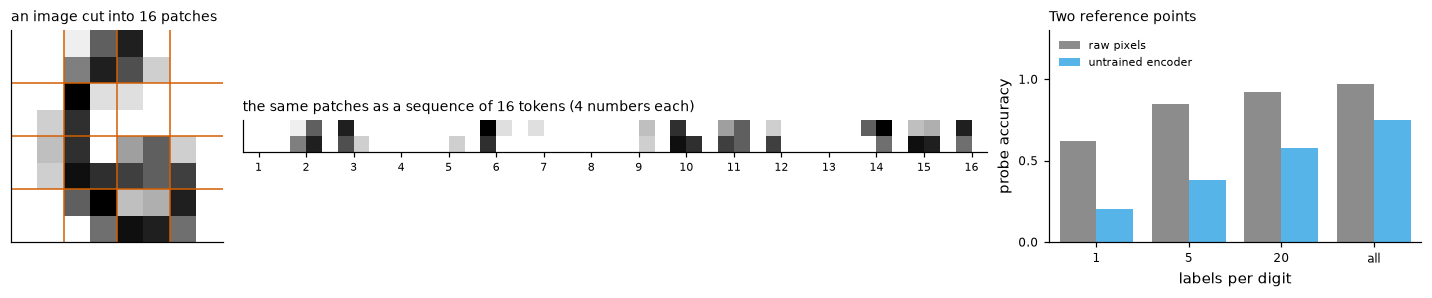

encoder: 101,888 parameters


,1 label per digit,5 labels per digit,20 labels per digit,"all 1,438 labels"
raw pixels,0.622,0.846,0.920,0.972
encoder with random weights,0.201,0.382,0.575,0.747


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 2.6), gridspec_kw=dict(width_ratios=[1, 3.2, 1.6]))
axes[0].imshow(Xte[0].view(8, 8), cmap="gray_r", vmin=-1, vmax=1)
for k in (1.5, 3.5, 5.5):
    axes[0].axhline(k, color=viz.VERMILION, lw=1); axes[0].axvline(k, color=viz.VERMILION, lw=1)
axes[0].set_xticks([]); axes[0].set_yticks([]); axes[0].set_title("an image cut into 16 patches", fontsize=9)
P = V.patchify(Xte[:1])[0]                                                      # (16, 4): the patches in reading order
strip = np.full((2, 16 * 3 - 1), np.nan)
for k in range(16):
    strip[:, k * 3:k * 3 + 2] = P[k].view(2, 2)
cmap = plt.get_cmap("gray_r").copy(); cmap.set_bad("white")
axes[1].imshow(strip, cmap=cmap, vmin=-1, vmax=1); axes[1].set_yticks([]); axes[1].set_xticks([k * 3 + 0.5 for k in range(16)]); axes[1].set_xticklabels(range(1, 17), fontsize=7)
axes[1].set_title("the same patches as a sequence of 16 tokens (4 numbers each)", fontsize=9)
set_seed(0); random_vit = V.ViT()
PROBES["encoder with random weights"] = probe_row(random_vit.features)
axes[2].bar(range(4), [PROBES["raw pixels"][k] for k in KS], width=0.4, color=viz.GREY, label="raw pixels")
axes[2].bar(np.arange(4) + 0.4, [PROBES["encoder with random weights"][k] for k in KS], width=0.4, color=viz.SKY, label="untrained encoder")
axes[2].set_xticks(np.arange(4) + 0.2); axes[2].set_xticklabels(["1", "5", "20", "all"]); axes[2].set_xlabel("labels per digit"); axes[2].set_ylabel("probe accuracy"); axes[2].set_ylim(0, 1.3); axes[2].set_yticks([0, 0.5, 1])
axes[2].set_title("Two reference points", fontsize=9); axes[2].legend(fontsize=7, loc="upper left")
plt.show()
print(f"encoder: {sum(p.numel() for p in random_vit.parameters()):,} parameters")
display(pd.DataFrame(PROBES).T.round(3))

**Two reference points**, before any pretraining.

* A linear classifier on the **raw pixels** is a strong baseline on this dataset: 0.62 with one labelled image per
  digit, 0.85 with five, 0.92 with twenty and 0.97 with all labels. Digits of 64 pixels are nearly linearly
  separable as they are. Every encoder below has to be compared with this row, and the bar is high.
* The **untrained encoder** is far below raw pixels (0.20 with one label per digit). Whatever a pretrained encoder
  scores above this row was put there by pretraining.

## 2. Masked autoencoding

BERT (notebook 04) hid 15% of the words and trained the model to fill them in. The masked autoencoder (MAE,
[He et al., 2021](https://arxiv.org/abs/2111.06377)) does the same with image patches, with three design choices of its own.

* **Hide most of the image.** MAE hides 75% of the patches, where BERT hid 15% of the words. Their argument: a
  missing word needs understanding to restore, but a missing patch can often be filled in from its neighbours,
  so the task is only hard enough when most of the image is gone.
* **The encoder sees only the visible patches.** Hidden patches are removed from the sequence, not replaced by a
  mask token. At 75% masking the encoder processes a quarter of the tokens.
* **A small decoder does the reconstruction.** It receives the encoded visible patches and a learned mask token at
  each hidden position, and predicts the hidden pixels. After pretraining the decoder is thrown away.

The loss is the squared error on the hidden patches. We pretrain four encoders with different mask ratios.

,error per hidden pixel,1 label per digit,5 labels per digit,20 labels per digit,"all 1,438 labels",training seconds
share of patches hidden,,,,,,
0.25,0.114,0.573,0.771,0.882,0.953,22.263
0.50,0.140,0.722,0.863,0.920,0.944,20.386
0.75,0.184,0.696,0.860,0.902,0.953,17.044
0.90,0.236,0.591,0.809,0.871,0.944,15.576


second seed at 0.5: {'1 label per digit': 0.73, '5 labels per digit': 0.877, '20 labels per digit': 0.918, 'all 1,438 labels': 0.961}


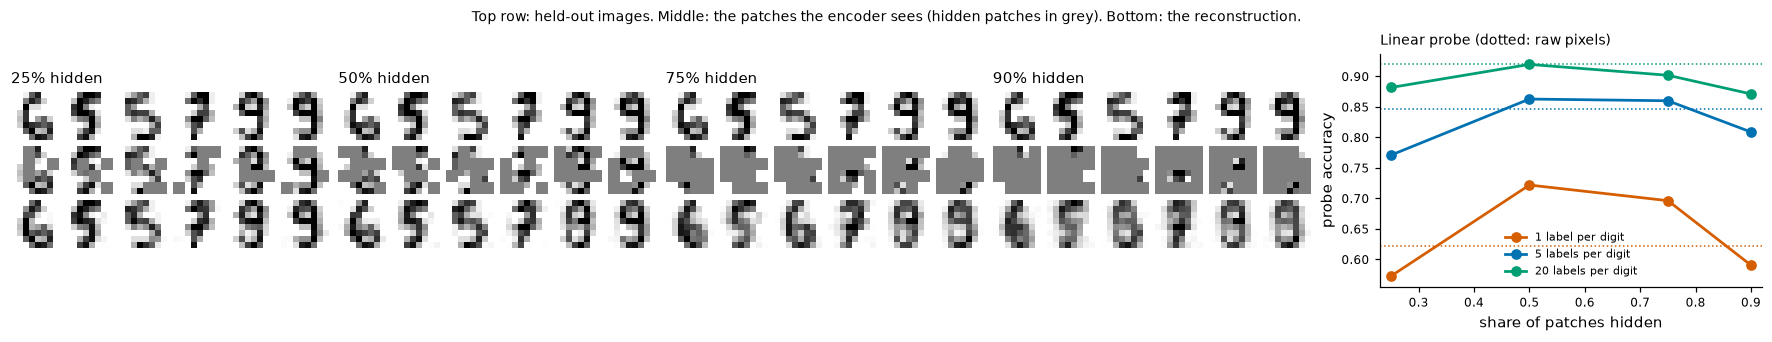

best mask ratio by the 5-label probe: 0.5


In [3]:
RATIOS = [0.25, 0.5, 0.75, 0.9]
maes = {}
for r in RATIOS:
    set_seed(0); vit = V.ViT(); mae = V.MAE(vit)
    out = V.train_mae(mae, Xtr, mask_ratio=r)
    seen, rec, hidden = mae.reconstruct(Xte, r)
    err = ((V.patchify(rec) - V.patchify(Xte)) ** 2).mean(-1)[hidden].mean()
    maes[r] = dict(mae=mae, vit=vit, seen=seen, rec=rec, seconds=out["seconds"], error=float(err), probe=probe_row(vit.features))
set_seed(1); vit_b = V.ViT(); V.train_mae(V.MAE(vit_b), Xtr, mask_ratio=0.5, seed=1)                  # a second seed of one setting
mae_table = pd.DataFrame({r: {"error per hidden pixel": maes[r]["error"], **maes[r]["probe"], "training seconds": maes[r]["seconds"]} for r in RATIOS}).T
mae_table.index.name = "share of patches hidden"
display(mae_table.round(3))
print("second seed at 0.5:", {k: round(v, 3) for k, v in probe_row(vit_b.features).items()})

fig, axes = plt.subplots(1, 5, figsize=(16, 3), gridspec_kw=dict(width_ratios=[1, 1, 1, 1, 1.2]))
for ax, r in zip(axes, RATIOS):
    tiles = torch.cat([Xte[:6], maes[r]["seen"][:6], maes[r]["rec"][:6]])                          # hidden patches are drawn mid-grey
    images.show_grid(tiles, nrow=6, ax=ax, title=f"{r:.0%} hidden")
ax = axes[4]
for name, col in (("1 label per digit", viz.VERMILION), ("5 labels per digit", viz.BLUE), ("20 labels per digit", viz.GREEN)):
    ax.plot(RATIOS, [maes[r]["probe"][name] for r in RATIOS], "o-", color=col, label=name)
    ax.axhline(PROBES["raw pixels"][name], color=col, ls=":", lw=1)
ax.set_xlabel("share of patches hidden"); ax.set_ylabel("probe accuracy"); ax.set_title("Linear probe (dotted: raw pixels)", fontsize=9); ax.legend(fontsize=7, loc="lower center")
fig.suptitle("Top row: held-out images. Middle: the patches the encoder sees (hidden patches in grey). Bottom: the reconstruction.", fontsize=9)
plt.show()
best_ratio = max(RATIOS, key=lambda r: maes[r]["probe"]["5 labels per digit"])
PROBES[f"MAE, {best_ratio:.0%} hidden"] = maes[best_ratio]["probe"]
print(f"best mask ratio by the 5-label probe: {best_ratio}")

**What happened.**

* **Reconstructions.** With 25% of the patches hidden the image is restored almost exactly. With 75% hidden the
  reconstruction is a blurred but plausible digit. With 90% hidden, one or two patches are visible and the
  reconstruction is close to an average digit. The error per hidden pixel rises from 0.11 to 0.24.
* **The probe prefers the middle.** Hiding 50% or 75% gives the best features: 0.72 and 0.70 with one label per
  digit, 0.86 and 0.86 with five. A second seed at 50% gives 0.73 and 0.88, so 50% and 75% cannot be told apart.
  Hiding 25% (0.57 and 0.77) or 90% (0.59 and 0.81) is clearly worse. This is the shape [He et al., 2021](https://arxiv.org/abs/2111.06377) reported: a task
  that is too easy teaches little, and so does one that is impossible. Their optimum of 75% was for images of 196
  patches; ours, with 16 patches, lies at 50 to 75%.
* **Against raw pixels the gain is small.** With one label per digit the best MAE features are ahead (0.72 against
  0.62). With five labels they are barely ahead (0.86 against 0.85), with twenty they are level (0.92), and with all
  labels they are behind (0.94 against 0.97). At 25% and 90% the features are worse than raw pixels at every number
  of labels.
* Hiding more is also cheaper, because the encoder processes only the visible patches (see the training times in
  the table).

### Try it: choose the share of patches hidden

Static preview at the default settings {'hidden': '75%', 'first_image': 0, 'seed': 0}. Run the notebook to get the controls.


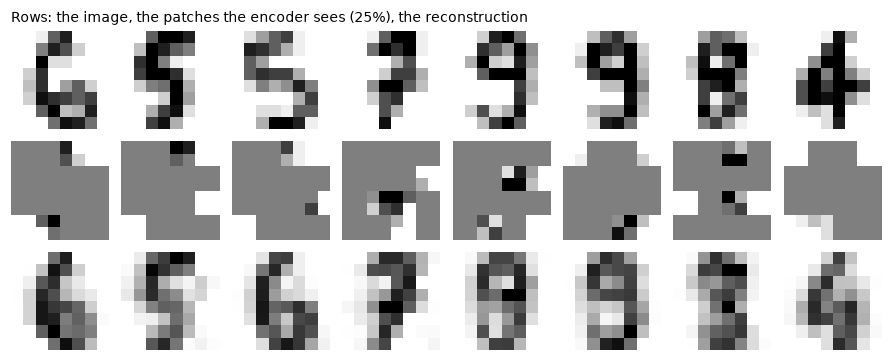

In [4]:
def mae_explorer(hidden="75%", first_image=0, seed=0):
    r = float(hidden.strip("%")) / 100
    seen, rec, _ = maes[r]["mae"].reconstruct(Xte[first_image:first_image + 8], r, seed=seed)
    fig, ax = plt.subplots(figsize=(8, 3.2))
    images.show_grid(torch.cat([Xte[first_image:first_image + 8], seen, rec]), nrow=8, ax=ax)
    ax.set_title(f"Rows: the image, the patches the encoder sees ({1 - r:.0%}), the reconstruction", fontsize=9)
    plt.show()
viz.explore(mae_explorer, hidden=["75%", "25%", "50%", "90%"], first_image=(0, 40, 8, 0), seed=(0, 9, 1, 0))

## 3. Contrastive learning

The second family does not reconstruct anything. SimCLR ([Chen et al., 2020](https://arxiv.org/abs/2002.05709)) makes two random **views** of each image
(shifted, rescaled, noised) and trains the encoder so that the two views of one image get similar features, and
views of different images get different ones. For a batch of $B$ images with views $a_i$ and $b_i$ and cosine
similarity $s$:

$$\mathcal{L} = -\frac{1}{B}\sum_i \log \frac{\exp\big(s(a_i, b_i)/\tau\big)}{\sum_j \exp\big(s(a_i, b_j)/\tau\big)} .$$

This is a classification: among the $B$ views in the batch, pick the one that came from the same image. It has the
form of the softmax loss of a language model, with the other images of the batch as the wrong answers.

The design choices are these.

* **The augmentations.** They define what the features must ignore. Whatever differs between two views of an image
  is, by construction, not to be encoded.
* **The temperature $\tau$.** A low temperature makes the loss concentrate on the hardest wrong answers.
* **The batch size.** Each image is compared with the other $B - 1$, so a larger batch is a harder task.
* **A projection head.** The loss is applied to the output of a small MLP on top of the encoder, and the MLP is
  thrown away afterwards. (Not tested here.)

Our views: a shift of up to one pixel in each direction, the amount of ink scaled by up to 30%, and Gaussian noise.

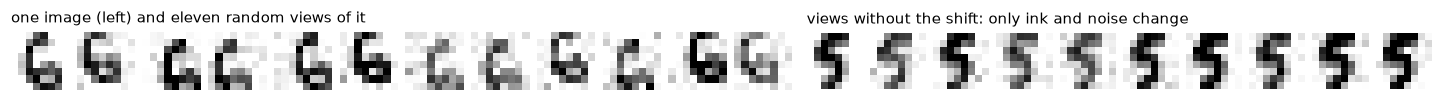

,1 label per digit,5 labels per digit,20 labels per digit,"all 1,438 labels",training seconds
"default (temperature 0.2, batch 128)",0.733,0.876,0.927,0.967,41.551
"default, second seed",0.719,0.883,0.934,0.975,41.559
temperature 1.0,0.643,0.768,0.869,0.950,41.891
no shift in the views,0.557,0.770,0.886,0.955,41.712
batch 32,0.510,0.711,0.820,0.922,21.546


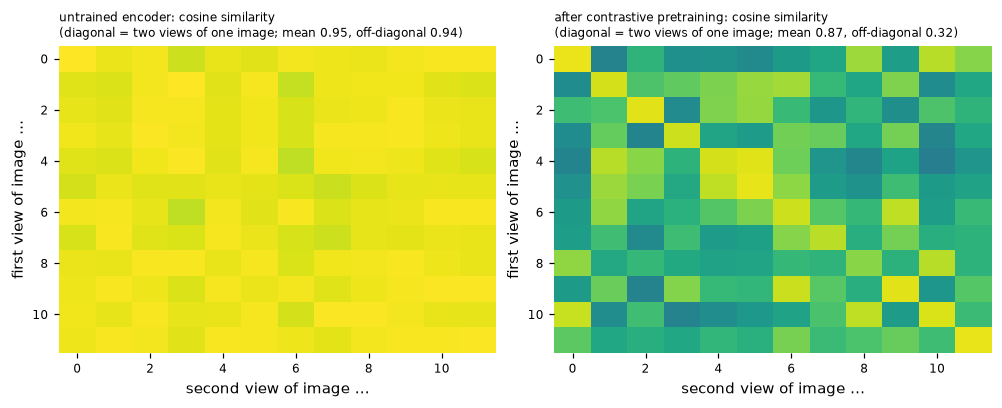

digits of the 12 images: [6, 5, 5, 7, 9, 9, 8, 4, 6, 8, 6, 0]
all held-out images, no augmentation: mean similarity of two different images of the same digit 0.76, of two images of different digits 0.33


In [5]:
g = torch.Generator().manual_seed(0)
fig, axes = plt.subplots(1, 2, figsize=(13, 1.9), gridspec_kw=dict(width_ratios=[1.25, 1]))
images.show_grid(torch.cat([Xte[:1], V.augment(Xte[:1].repeat(11, 1), generator=g)]), nrow=12, ax=axes[0], title="one image (left) and eleven random views of it")
images.show_grid(torch.cat([Xte[1:2], V.augment(Xte[1:2].repeat(9, 1), shift=0, generator=g)]), nrow=10, ax=axes[1], title="views without the shift: only ink and noise change")
plt.show()

CONTRASTIVE = {"default (temperature 0.2, batch 128)": {}, "default, second seed": dict(seed=1), "temperature 1.0": dict(temperature=1.0),
               "no shift in the views": dict(shift=0), "batch 32": dict(batch=32)}
con = {}
for name, kw in CONTRASTIVE.items():
    set_seed(kw.get("seed", 0)); vit = V.ViT()
    out = V.train_contrastive(vit, Xtr, **kw)
    con[name] = dict(vit=vit, seconds=out["seconds"], probe=probe_row(vit.features))
display(pd.DataFrame({n: {**c["probe"], "training seconds": c["seconds"]} for n, c in con.items()}).T.round(3))
contrastive_vit = con["default (temperature 0.2, batch 128)"]["vit"]
PROBES["contrastive"] = con["default (temperature 0.2, batch 128)"]["probe"]

# What the loss sees: similarities between two views of 12 images, before and after training.
va, vb = V.augment(Xte[:12], generator=g), V.augment(Xte[:12], generator=g)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, (enc, title) in zip(axes, ((random_vit, "untrained encoder"), (contrastive_vit, "after contrastive pretraining"))):
    with torch.no_grad():
        S = F.normalize(enc(va), dim=-1) @ F.normalize(enc(vb), dim=-1).T
    viz.heat(ax, S.numpy(), cmap="viridis", vmin=-1, vmax=1); ax.set_xlabel("second view of image ..."); ax.set_ylabel("first view of image ...")
    ax.set_title(f"{title}: cosine similarity\n(diagonal = two views of one image; mean {float(S.diag().mean()):.2f}, off-diagonal {float((S.sum() - S.diag().sum()) / 132):.2f})", fontsize=8)
plt.show()
print("digits of the 12 images:", yte[:12].tolist())
with torch.no_grad():
    f = F.normalize(contrastive_vit(Xte), dim=-1); S = f @ f.T
same = yte[:, None] == yte[None, :]; other = ~torch.eye(N, dtype=torch.bool)
print(f"all held-out images, no augmentation: mean similarity of two different images of the same digit {float(S[same & other].mean()):.2f}, of two images of different digits {float(S[~same].mean()):.2f}")

**What happened.**

* **The loss did what it says.** For the untrained encoder all images are alike: two views of one image have a
  cosine similarity of 0.95, and views of different images 0.94. After training, two views of one image are at 0.87
  and views of different images at 0.32.
* **Digits group together although the loss never mentions them.** Over all held-out images, without
  augmentation, two different images of the same digit have a mean similarity of 0.76, and images of different digits
  0.33. The loss only asks for two views of one image to agree. Images of the same digit end up close because a
  shifted, noised view of one four looks much like another four.
* **Features.** 0.73 with one label per digit, 0.88 with five and 0.93 with twenty (second seed: 0.72, 0.88, 0.93).
  That is level with the MAE (0.72, 0.86, 0.92) and, with one label, eleven points above raw pixels (0.62). With
  twenty labels or all of them it is level with raw pixels.
* **The views matter most.** Without the shift the features fall to 0.56 and 0.77, below raw pixels. What the views
  vary is what the features are trained to ignore. An interpretation of this result: when the two views are
  aligned pixel for pixel, they can be matched by position alone, and nothing forces the encoder to represent the
  shape of the digit.
* **Temperature.** At a temperature of 1.0 the features are worse (0.64 and 0.77).
* **Batch size.** A batch of 32 gives much worse features (0.51 and 0.71). This run does not say why. A smaller
  batch offers fewer wrong answers per image, and at the same number of steps it also sees a quarter of the
  images. Section 5 separates these two effects for the text-image model.

## 4. What pretraining bought

Three ways to get a digit classifier from few labels:

* **a linear probe** on the frozen features of a pretrained encoder;
* **fine-tuning** the pretrained encoder on the labelled images;
* **training the same encoder from scratch** on the labelled images alone, which is what one would do without
  pretraining.

,1 label per digit,5 labels per digit,20 labels per digit,"all 1,438 labels"
raw pixels,0.622,0.846,0.920,0.972
encoder with random weights,0.201,0.382,0.575,0.747
same encoder trained from scratch on the labels,0.190,0.487,0.706,0.964
"MAE, 50% hidden",0.722,0.863,0.920,0.944
"MAE, fine-tuned",0.577,0.881,0.929,0.969
contrastive,0.733,0.876,0.927,0.967
"contrastive, fine-tuned",0.718,0.878,0.943,0.981


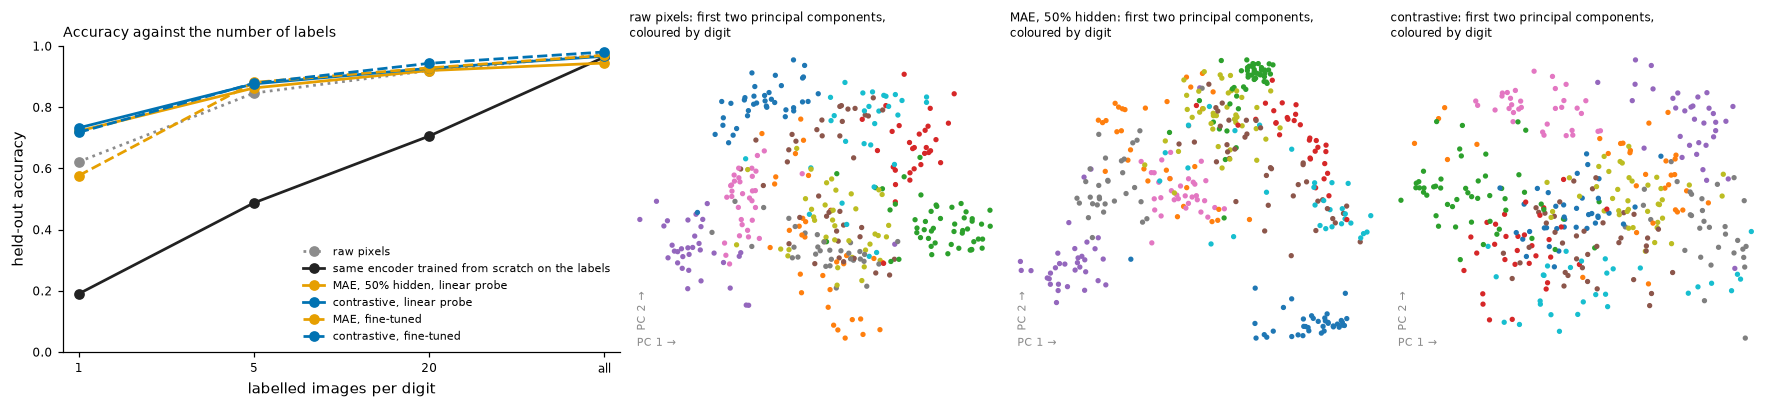

In [6]:
def from_labels(base, per_class, seeds=(0, 1, 2)):
    # train (base=None) or fine-tune (base = a pretrained encoder) on per_class labelled images per digit; mean held-out accuracy over three draws.
    # With few labels 300 steps are plenty. With all 1,438 labels we train for 1,500 steps (one run), so that the encoder trained from scratch is not cut short.
    accs, steps = [], 300 if per_class else 1500
    for s in (seeds if per_class else seeds[:1]):
        idx = V.few_labels(ytr, per_class, s) if per_class else torch.arange(len(ytr))
        set_seed(s); vit = V.ViT() if base is None else copy.deepcopy(base)
        predict = V.train_supervised(vit, Xtr[idx], ytr[idx], steps=steps, seed=s, lr=2e-3 if base is None else 5e-4)
        with torch.no_grad():
            accs.append(float((predict(Xte) == yte).float().mean()))
    return float(np.mean(accs))
mae_vit = maes[best_ratio]["vit"]
rows = dict(PROBES)
rows["same encoder trained from scratch on the labels"] = {name: from_labels(None, k) for name, k in KS.items()}
rows["MAE, fine-tuned"] = {name: from_labels(mae_vit, k) for name, k in KS.items()}
rows["contrastive, fine-tuned"] = {name: from_labels(contrastive_vit, k) for name, k in KS.items()}
order = ["raw pixels", "encoder with random weights", "same encoder trained from scratch on the labels", f"MAE, {best_ratio:.0%} hidden", "MAE, fine-tuned", "contrastive", "contrastive, fine-tuned"]
bought = pd.DataFrame(rows).T.loc[order]
display(bought.round(3))

fig = plt.figure(figsize=(16, 3.6)); gs = fig.add_gridspec(1, 4, width_ratios=[1.5, 1, 1, 1])
ax = fig.add_subplot(gs[0])
style = {"raw pixels": (viz.GREY, ":"), "same encoder trained from scratch on the labels": (viz.BLACK, "-"), f"MAE, {best_ratio:.0%} hidden": (viz.ORANGE, "-"), "contrastive": (viz.BLUE, "-"),
         "MAE, fine-tuned": (viz.ORANGE, "--"), "contrastive, fine-tuned": (viz.BLUE, "--")}
for name, (col, ls) in style.items():
    ax.plot(range(4), bought.loc[name], "o", ls=ls, color=col, label=name if "fine" in name or name in ("raw pixels", "same encoder trained from scratch on the labels") else name + ", linear probe")
ax.set_xticks(range(4)); ax.set_xticklabels(["1", "5", "20", "all"]); ax.set_xlabel("labelled images per digit"); ax.set_ylabel("held-out accuracy"); ax.set_ylim(0, 1)
ax.set_title("Accuracy against the number of labels", fontsize=9); ax.legend(fontsize=7, loc="lower right")
for k, (name, feats) in enumerate((("raw pixels", Xte), (f"MAE, {best_ratio:.0%} hidden", mae_vit.features(Xte)), ("contrastive", contrastive_vit.features(Xte)))):
    ax = fig.add_subplot(gs[k + 1]); xy = viz.pca2(feats.numpy())
    ax.scatter(xy[:, 0], xy[:, 1], s=6, c=yte, cmap="tab10"); viz.embedding_axes(ax); ax.set_title(f"{name}: first two principal components,\ncoloured by digit", fontsize=8)
plt.show()
torch.save(dict(state=contrastive_vit.state_dict(), config=dict(d=64, depth=3, patch=2)), os.path.join(CKPT_DIR, "vision_encoder.pt"))

**Reading the table and the figure.**

* **Against the same encoder trained from scratch, pretraining is worth a great deal.** With one label per digit
  the encoder trained from scratch reaches 0.19, and a linear probe on the contrastive encoder 0.73. With five
  labels: 0.49 against 0.88. With twenty: 0.71 against 0.93. A transformer has no built-in knowledge of images, and
  it cannot acquire it from ten examples.
* **Against a linear classifier on raw pixels, it is worth much less** (0.62, 0.85 and 0.92). The honest summary for
  this dataset: pretraining gave about ten points with one label per digit and almost nothing beyond five. On 8×8
  digits there is little for an encoder to add. On natural images a linear classifier on pixels is useless, and
  there the same methods are what made vision transformers practical; that statement rests on the cited papers and
  not on this notebook.
* **Fine-tuning did not beat the linear probe with few labels.** For the contrastive encoder the two are level
  (0.72 against 0.73 with one label, 0.88 against 0.88 with five). For the MAE, fine-tuning is worse with one label
  (0.58 against 0.72). With ten labelled images, updating 100,000 weights can undo what pretraining learned.
* **With all 1,438 labels, pretraining no longer matters.** The encoder trained from scratch reaches 0.96, the
  fine-tuned MAE 0.97 and the fine-tuned contrastive encoder 0.98 (single runs of 1,500 steps), and raw pixels
  0.97. Pretraining is a way of saving labels, and here it saved them only when they were very few.
* The scatter plots show two directions of a 64-dimensional feature space and should not be over-read. The probe
  accuracies are the measurement.

# Part B · A model that matches images with text

## 5. Captioned digits and the contrastive text-image loss

CLIP ([Radford et al., 2021](https://arxiv.org/abs/2103.00020)) applies the contrastive idea of section 3 to two different kinds of input. One encoder
embeds images, another embeds captions, and the pair is trained on 400 million images with their captions from the
web so that an image and its own caption are more similar than the image and any other caption in the batch. No
class labels are used. The supervision is the text that happened to accompany the image.

**Our data.** Every digit image is used in two styles: as it is ("thin") and with thickened strokes ("bold"). A
caption is generated for it from seven templates, with the digit written as a word or as a numeral and the style
named by one of three synonyms. Two of the templates do not mention the style. A caption therefore names the digit,
but the model is never given a label.

**Two losses.**

* **Softmax** (CLIP): for each image, a classification over the captions of the batch, and for each caption a
  classification over the images. This is the loss of section 3.
* **Sigmoid** (SigLIP, [Zhai et al., 2023](https://arxiv.org/abs/2303.15343)): each of the $B^2$ image-caption pairs of a batch is its own yes-or-no
  question. Nothing has to be normalised over the batch, which makes very large batches cheaper, and the authors
  report better results at small batch sizes.

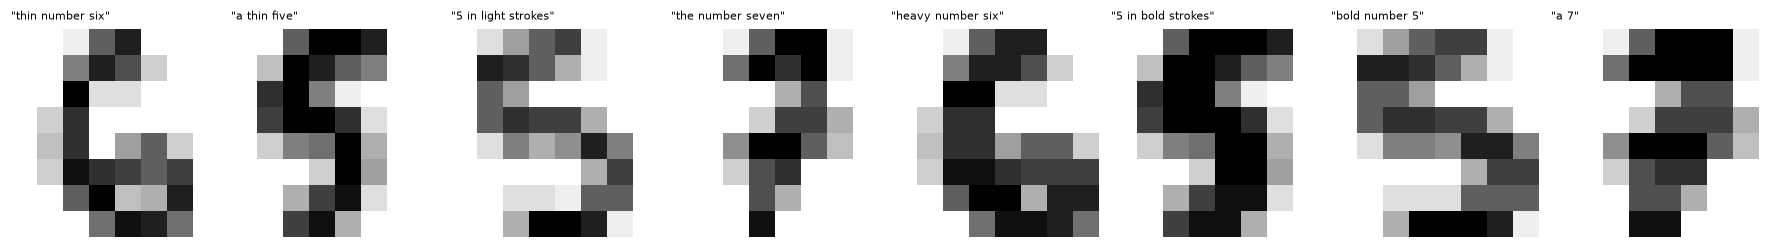

2876 training images (two styles), vocabulary of 35 words; five captions of one bold three:
['a thick 3', 'thick number three', 'a bold three', 'thick number three', 'a three']


zero-shot accuracy, digit  zero-shot accuracy, digit and style  training seconds
softmax batch 16                       0.450                                0.450             7.987
        batch 64                       0.919                                0.912            13.023
        batch 256                      0.972                                0.955            29.117
sigmoid batch 16                       0.372                                0.347             8.052
        batch 64                       0.875                                0.862            13.254
        batch 256                      0.958                                0.946            29.318

softmax, batch 16 for 4,000 steps (64,000 pairs, as batch 64 for 1,000 steps): zero-shot digit accuracy 0.932


In [7]:
Xc, dc, sc = V.captioned_digits(Xtr, ytr)            # training images in both styles, with digit and style of each
Xct, dct, sct = V.captioned_digits(Xte, yte)         # the same for the held-out images
rng = np.random.default_rng(0)
show = [0, 1, 2, 3, len(Xte), len(Xte) + 1, len(Xte) + 2, len(Xte) + 3]
fig, axes = plt.subplots(1, 8, figsize=(16, 2.1))
for ax, i in zip(axes, show):
    ax.imshow(Xct[i].view(8, 8), cmap="gray_r", vmin=-1, vmax=1); ax.axis("off"); ax.set_title('"' + V.caption(int(dct[i]), int(sct[i]), rng) + '"', fontsize=7)
plt.show()
print(f"{len(Xc)} training images (two styles), vocabulary of {len(V.VOCAB) - 1} words; five captions of one bold three:")
print([V.caption(3, 1, rng) for _ in range(5)])

clips = {}
for loss in ("softmax", "sigmoid"):
    for batch in (16, 64, 256):
        set_seed(0); model = V.CLIP(loss=loss)
        out = V.train_clip(model, Xc, dc, sc, steps=1000, batch=batch)
        clips[(loss, batch)] = dict(model=model, seconds=out["seconds"], digit=V.zero_shot(model, Xct, dct), both=V.zero_shot(model, Xct, dct, sct))
set_seed(0); same_pairs = V.CLIP(); V.train_clip(same_pairs, Xc, dc, sc, steps=4000, batch=16)      # batch 16 for 4,000 steps: as many pairs as batch 64 for 1,000
grid = pd.DataFrame({(loss, f"batch {b}"): {"zero-shot accuracy, digit": c["digit"], "zero-shot accuracy, digit and style": c["both"], "training seconds": c["seconds"]} for (loss, b), c in clips.items()}).T
display(grid.round(3))
print(f"softmax, batch 16 for 4,000 steps (64,000 pairs, as batch 64 for 1,000 steps): zero-shot digit accuracy {V.zero_shot(same_pairs, Xct, dct):.3f}")
clip = clips[("softmax", 256)]["model"]
torch.save(clip.state_dict(), os.path.join(CKPT_DIR, "clip.pt"))

**Zero-shot classification** is how the numbers above were obtained. Nothing is trained. To classify an image, embed
it, embed the ten prompts "a zero", "a one", ..., "a nine", and answer with the prompt whose embedding is most
similar. The class names are the only thing that connects the model to the task.

**What happened.**

* **It works without labels.** Trained with a batch of 256, the softmax model classifies 0.97 of the held-out
  images correctly by digit, and 0.96 by digit and style together (20 classes), from prompts alone.
* **Softmax against sigmoid.** The softmax loss was ahead at every batch size: 0.45 against 0.37 at 16, 0.92
  against 0.88 at 64, 0.97 against 0.96 at 256. These are single runs, and the last difference is small. The
  advantage of the sigmoid loss at small batches that [Zhai et al., 2023](https://arxiv.org/abs/2303.15343) report did not appear here.
* **Batch size, or amount of data?** Larger batches look much better in the table. But every run took 1,000 steps,
  so a batch of 256 saw sixteen times as many pairs as a batch of 16. The extra run separates the two effects. A
  batch of 16 trained for 4,000 steps sees as many pairs as a batch of 64 for 1,000 steps, and it reaches 0.93
  against 0.92. At equal data the small batch was no worse. In our setting the benefit of a large batch was the
  data it brought, not the larger number of wrong answers to compare with.
* **A caveat about our data.** There are only 20 combinations of digit and style. In a batch of 256, about a dozen
  other images have a caption that would fit a given image equally well, and the loss counts all of them as wrong
  answers. Web data has far fewer such collisions, so our conclusion about batch size should not be carried over to
  CLIP itself.

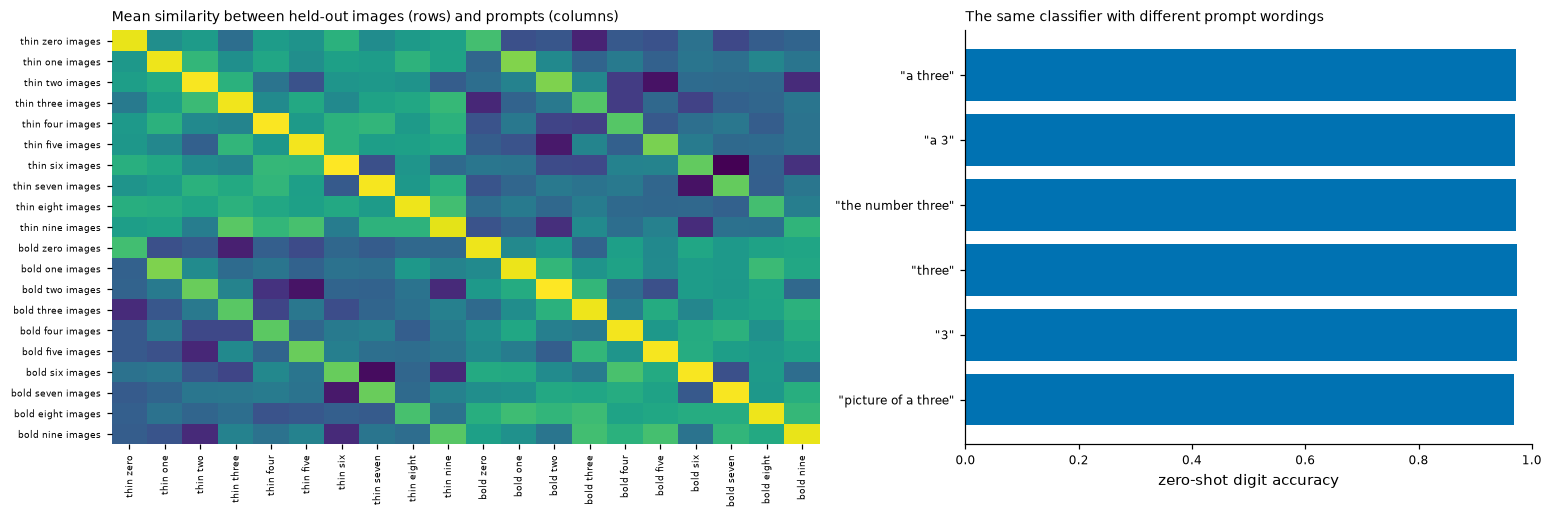

{'"a three"': 0.972, '"a 3"': 0.971, '"the number three"': 0.972, '"three"': 0.974, '"3"': 0.974, '"picture of a three"': 0.968}
similarity of text embeddings to "a bold three": {'a thick three': np.float32(0.99), 'a heavy three': np.float32(0.99), 'a bold 3': np.float32(0.98), 'a thin three': np.float32(0.4), 'a bold eight': np.float32(0.43)}


In [8]:
prompts20 = [f"a {V.STYLE_WORDS[s][0]} {w}" for s in (0, 1) for w in V.DIGIT_WORDS]
S = clip.similarity(Xct, prompts20)
groups = torch.stack([S[(sct == s) & (dct == d)].mean(0) for s in (0, 1) for d in range(10)])           # 20 groups of images x 20 prompts
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw=dict(width_ratios=[1.25, 1]))
viz.heat(axes[0], groups.numpy(), xlabels=[p[2:] for p in prompts20], ylabels=[p[2:] + " images" for p in prompts20], cmap="viridis")
axes[0].tick_params(axis="x", labelsize=6, rotation=90); axes[0].tick_params(axis="y", labelsize=6)
axes[0].set_title("Mean similarity between held-out images (rows) and prompts (columns)", fontsize=9)
wordings = {'"a three"': [f"a {w}" for w in V.DIGIT_WORDS], '"a 3"': [f"a {i}" for i in range(10)], '"the number three"': [f"the number {w}" for w in V.DIGIT_WORDS],
            '"three"': list(V.DIGIT_WORDS), '"3"': [str(i) for i in range(10)], '"picture of a three"': [f"picture of a {w}" for w in V.DIGIT_WORDS]}
acc = {k: float((clip.similarity(Xct, v).argmax(1) == dct).float().mean()) for k, v in wordings.items()}
axes[1].barh(list(acc)[::-1], list(acc.values())[::-1], color=viz.BLUE); axes[1].set_xlim(0, 1); axes[1].set_xlabel("zero-shot digit accuracy")
axes[1].set_title("The same classifier with different prompt wordings", fontsize=9)
plt.show()
print({k: round(v, 3) for k, v in acc.items()})
text = clip.embed_text(torch.stack([V.encode_caption(t) for t in ("a bold three", "a thick three", "a heavy three", "a bold 3", "a thin three", "a bold eight")]))
print('similarity of text embeddings to "a bold three":', dict(zip(("a thick three", "a heavy three", "a bold 3", "a thin three", "a bold eight"), np.round((text @ text[0]).detach().numpy()[1:], 2))))
PROBES["CLIP image encoder"] = probe_row(clip.image.features)

**Reading the figures.**

* **The heat map** has a bright diagonal: each group of images is most similar to its own prompt. The two fainter
  diagonals in the off-diagonal blocks are the same digit in the other style: thin threes are more similar to
  "a bold three" than to the other bold prompts.
* **The wording of the prompt hardly matters**: 0.97 for all six wordings, including the bare word and the bare
  numeral, neither of which ever occurred alone as a caption.
* **The model learned synonyms from images.** The text embedding of "a thick three" has a cosine similarity of
  0.99 with that of "a bold three", and "a bold 3" has 0.98. "A thin three" has 0.40 and "a bold eight" 0.43. Nothing
  told the model that "thick" and "bold" mean the same, or that "3" and "three" do. They were used for the same
  images. Section 8 depends on this property.

### Try it: search the held-out images with a caption

Static preview at the default settings {'style': 'bold', 'digit': 'three', 'wording': 'a {style} {digit}'}. Run the notebook to get the controls.


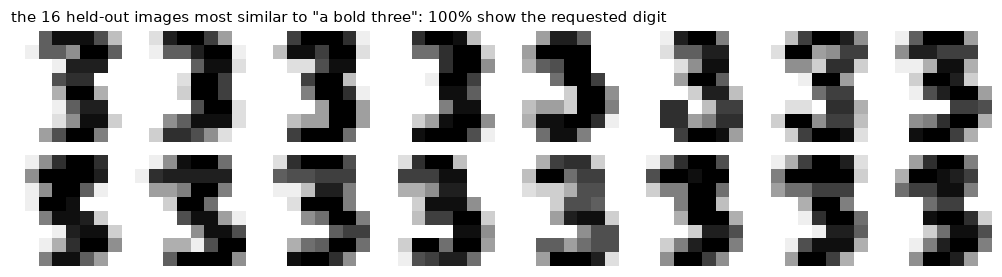

In [9]:
def caption_explorer(style="bold", digit="three", wording="a {style} {digit}"):
    text = " ".join(wording.format(style=style, digit=digit).split())
    sim = clip.similarity(Xct, [text])[:, 0]
    top = sim.argsort(descending=True)[:16]
    want_d = V.DIGIT_WORDS.index(digit) if digit in V.DIGIT_WORDS else int(digit)
    right = float((dct[top] == want_d).float().mean())
    fig, ax = plt.subplots(figsize=(9, 2.6))
    images.show_grid(Xct[top], nrow=8, ax=ax, title=f'the 16 held-out images most similar to "{text}": {right:.0%} show the requested digit')
    plt.show()
viz.explore(caption_explorer, style=["bold", "thin", "thick", "fine", "heavy", "light"], digit=["three"] + [w for w in V.DIGIT_WORDS if w != "three"] + [str(i) for i in range(10)],
            wording=["a {style} {digit}", "the digit {digit} drawn in {style} strokes", "a {digit}", "{digit} in {style} strokes"])

## 6. What the text-image model does not learn: combinations it has not seen

A caption names a digit and a style. Does the model learn the two as separate things that can be recombined? We
remove four combinations from training (bold sevens, bold threes, thin zeros and thin fives), train again, and
then ask the model to classify held-out images of exactly those combinations. It has seen sevens (thin ones) and
bold digits (other ones), but never a bold seven.

,held-out images,digit and style right,style right,digit right (prompts without style),most common answers
bold seven,32,0.71875,0.90625,0.8125,"bold seven (23), thin seven (3)"
bold three,31,0.451613,0.935484,0.16129,"bold three (14), bold five (12)"
thin zero,38,0.131579,1.0,0.131579,"thin eight (25), thin zero (5)"
thin five,39,0.538462,1.0,0.307692,"thin five (21), thin three (17)"


combinations seen in training: digit and style right for 0.952 of 578 held-out images
combinations never seen:       digit and style right for 0.450 of 140 held-out images


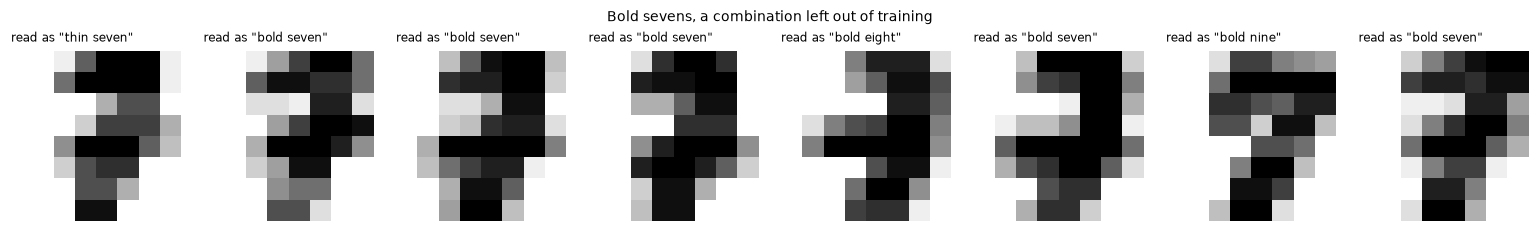

In [10]:
HOLD = [(7, 1), (3, 1), (0, 0), (5, 0)]
Xh, dh, sh = V.captioned_digits(Xtr, ytr, holdout=HOLD)
set_seed(0); clip_h = V.CLIP(); V.train_clip(clip_h, Xh, dh, sh, steps=1000, batch=256)
unseen = torch.zeros(len(Xct), dtype=torch.bool)
for d, s in HOLD:
    unseen |= (dct == d) & (sct == s)
rows = {}
for d, s in HOLD:
    sel = (dct == d) & (sct == s)
    p20 = clip_h.similarity(Xct[sel], prompts20).argmax(1); c20 = torch.bincount(p20, minlength=20)
    p10 = clip_h.similarity(Xct[sel], [f"a {w}" for w in V.DIGIT_WORDS]).argmax(1)
    rows[f"{V.STYLE_WORDS[s][0]} {V.DIGIT_WORDS[d]}"] = {"held-out images": int(sel.sum()), "digit and style right": float(((p20 % 10 == d) & (p20 // 10 == s)).float().mean()),
                                                         "style right": float((p20 // 10 == s).float().mean()), "digit right (prompts without style)": float((p10 == d).float().mean()),
                                                         "most common answers": ", ".join(f"{prompts20[int(i)][2:]} ({int(c20[i])})" for i in c20.argsort(descending=True)[:2])}
display(pd.DataFrame(rows).T)
print(f"combinations seen in training: digit and style right for {V.zero_shot(clip_h, Xct[~unseen], dct[~unseen], sct[~unseen]):.3f} of {int((~unseen).sum())} held-out images")
print(f"combinations never seen:       digit and style right for {V.zero_shot(clip_h, Xct[unseen], dct[unseen], sct[unseen]):.3f} of {int(unseen.sum())} held-out images")
sel = torch.nonzero((dct == 7) & (sct == 1))[:8, 0]
pred = clip_h.similarity(Xct[sel], prompts20).argmax(1)
fig, axes = plt.subplots(1, 8, figsize=(14, 2))
for ax, i, p in zip(axes, sel, pred):
    ax.imshow(Xct[i].view(8, 8), cmap="gray_r", vmin=-1, vmax=1); ax.axis("off"); ax.set_title(f'read as "{prompts20[int(p)][2:]}"', fontsize=8)
fig.suptitle("Bold sevens, a combination left out of training", fontsize=9)
plt.show()

**What happened.** On combinations seen in training, digit and style are right for 0.95 of the held-out images. On
the four combinations never seen, for 0.45. Chance is 0.05, so something transfers, and a good deal does not.

* **The style transfers.** It is right for 0.91 to 1.00 of the images of each unseen combination.
* **The digit often does not.** Digit and style are right for 0.72 of the bold sevens, 0.54 of the thin fives (17
  of 39 are called thin threes), 0.45 of the bold threes (12 of 31 are called bold fives) and 0.13 of the thin
  zeros (25 of 38 are called thin eights).

So the model did not learn "zero" as something independent of the style it was drawn in. It learned what the zeros
it saw looked like, and those were all bold. Weak handling of unfamiliar combinations has been reported for the
real CLIP as well, and a text-to-image system inherits it from its text encoder. Ours is a small test (four
combinations, 140 images, one training run), and the numbers would differ for other choices.

# Part C · The autoencoder, and diffusion on its codes

## 7. Design choice: how to regularise the codes

Diffusion on pixels spends most of its capacity and compute on detail that the eye barely notices. **Latent
diffusion** ([Rombach et al., 2021](https://arxiv.org/abs/2112.10752)) splits the work. First an autoencoder compresses each image to a small code and learns
to turn codes back into images. Then the diffusion model is trained on the codes. For a 512×512 image with a
downsampling factor of 8, the denoiser works on 64×64×4 numbers, about 48 times fewer than the pixels.

This is the autoencoder of notebook 06 with its problem turned into a requirement. There, we wanted to sample codes
from a fixed prior, and that needed a strong KL term, which blurred the images. Here a second model learns the
distribution of the codes, so the codes only have to be *easy for a diffusion model to learn*: no wild scales, no
isolated outliers. Two mild regularisers are in use.

* **KL with a very small weight** ([Rombach et al., 2021](https://arxiv.org/abs/2112.10752)): the VAE loss of notebook 06 with the KL term multiplied by
  something like $10^{-6}$.
* **Vector quantisation** ([Oord et al., 2017](https://arxiv.org/abs/1711.00937), [Esser et al., 2020](https://arxiv.org/abs/2012.09841)): the code is a few tokens, and each token is replaced by the
  nearest vector of a learned codebook. An image then becomes a short sequence of integers, which an autoregressive
  transformer can also model (notebook 10).

One more detail of the released models is tested: the codes are divided by a fixed number, the **scale factor**, so
that their standard deviation is 1 and the noise schedule designed for unit-variance data fits them.

We compress the 64 pixels to a code of 16 numbers with six autoencoders, train the same denoiser (the final recipe
of notebook 07, with class labels) on the codes of each, and decode its samples.

,reconstruction error,FD of reconstructions,standard deviation of the codes,samples: fd,precision,coverage,nn_ratio,seconds: autoencoder,seconds: denoiser
no regulariser,1.61,2.05,2.80,6.50,0.96,0.98,0.93,2.99,14.08
KL weight 0.01,1.50,2.60,1.24,6.78,0.97,0.94,0.96,3.25,14.03
KL weight 0.1,2.07,6.29,0.83,10.02,0.97,0.96,0.95,3.26,13.62
KL weight 1,4.86,41.86,0.51,40.12,0.90,0.72,0.96,2.99,13.54
VQ: 4 tokens from 64 codes (24 bits),3.35,6.22,1.42,12.15,0.96,0.90,0.93,3.23,13.59
VQ: 8 tokens from 64 codes (48 bits),1.84,3.10,1.25,8.69,0.94,0.93,0.93,3.26,13.72


diffusion on pixels, same denoiser and steps: FD 7.8, precision 0.96, coverage 0.94, nn_ratio 0.92; 14 s
no regulariser, codes not rescaled (standard deviation 2.80): FD 7.1, precision 0.95, coverage 0.95, judge reads the requested digit 0.89 (rescaled: 0.92)


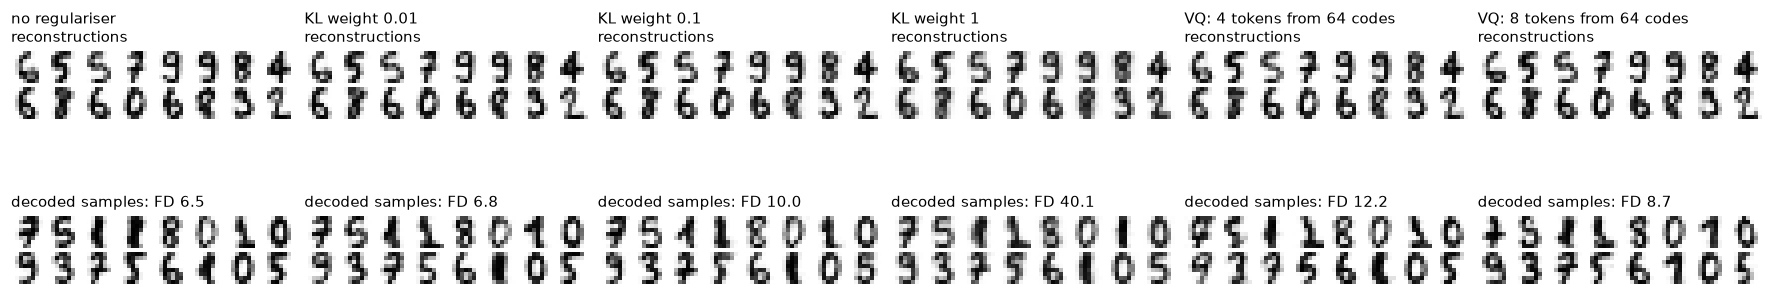

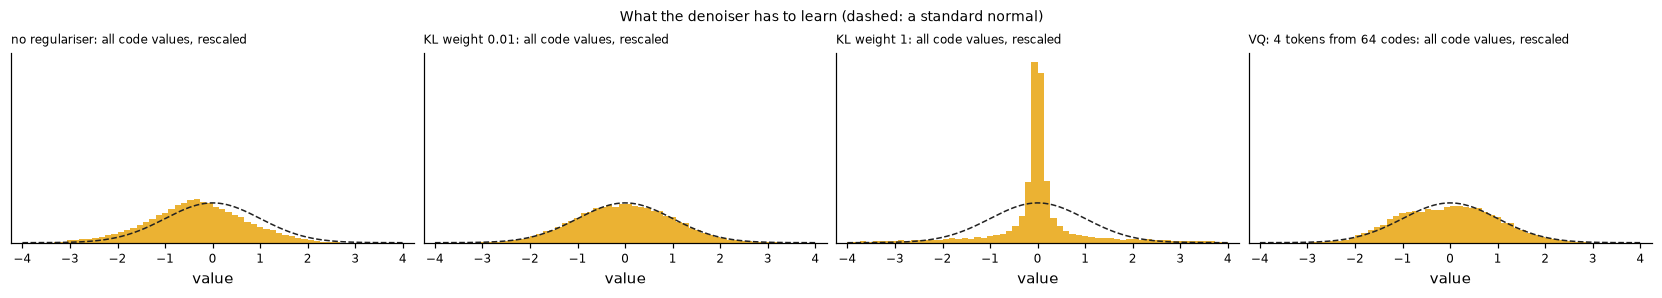

In [11]:
FINAL = dict(schedule="cosine", pred="x0", weighting="min-snr")
ROWS = {}
def score(x, name, nfe=50, keep=True):
    row = card.evaluate(x, name, nfe=nfe, labels=LABELS); card.rows.pop()
    if keep:
        ROWS[name] = row
    return row

def latent_diffusion(ae, scale=True, seed=0):
    # the denoiser of notebook 07 on the codes of `ae`; returns decoded samples for the labels in LABELS
    lat = L.Latents(ae, Xtr, scale=scale); diff = D.Diffusion(**FINAL)
    set_seed(seed); model = D.Denoiser(128, 3, d_in=ae.z_dim)
    out = D.train(model, diff, lat.z, ytr, steps=3000, seed=seed)
    return dict(samples=lat.decode(diff.sample(out["model"], LABELS, steps=50, clip=False)), lat=lat, diff=diff, model=out["model"], seconds=out["seconds"])

set_seed(0); pixel_model = D.Denoiser(128, 3); pixel_diff = D.Diffusion(**FINAL)
pixel = D.train(pixel_model, pixel_diff, Xtr, ytr, steps=3000, seed=0)
score(pixel_diff.sample(pixel["model"], LABELS, steps=50), "diffusion on pixels (notebook 07 recipe)")

AES = {"no regulariser": ("kl", 0.0, {}), "KL weight 0.01": ("kl", 0.01, {}), "KL weight 0.1": ("kl", 0.1, {}), "KL weight 1": ("kl", 1.0, {}),
       "VQ: 4 tokens from 64 codes (24 bits)": ("vq", 0.25, dict(n_codes=64, code_dim=4)), "VQ: 8 tokens from 64 codes (48 bits)": ("vq", 0.25, dict(n_codes=64, code_dim=2))}
aes = {}
for name, (kind, weight, kw) in AES.items():
    set_seed(0); ae = L.Autoencoder(16, kind, **kw)
    t = L.train_autoencoder(ae, Xtr, weight=weight)
    rec = ae.reconstruct(Xte); ld = latent_diffusion(ae)
    r = score(ld["samples"], f"latent diffusion, {name}")
    aes[name] = dict(ae=ae, rec=rec, **ld, row={"reconstruction error": float(((rec - Xte) ** 2).sum(1).mean()), "FD of reconstructions": score(rec, "rec", keep=False)["fd"],
                                                "standard deviation of the codes": ld["lat"].factor, "samples: fd": r["fd"], "precision": r["precision"], "coverage": r["coverage"], "nn_ratio": r["nn_ratio"],
                                                "seconds: autoencoder": t["seconds"], "seconds: denoiser": ld["seconds"]})
unscaled = latent_diffusion(aes["no regulariser"]["ae"], scale=False)
r = score(unscaled["samples"], "latent diffusion, no regulariser, codes not rescaled")
ae_table = pd.DataFrame({n: a["row"] for n, a in aes.items()}).T
display(ae_table.round(2))
p = ROWS["diffusion on pixels (notebook 07 recipe)"]
print(f"diffusion on pixels, same denoiser and steps: FD {p['fd']:.1f}, precision {p['precision']:.2f}, coverage {p['coverage']:.2f}, nn_ratio {p['nn_ratio']:.2f}; {pixel['seconds']:.0f} s")
print(f"no regulariser, codes not rescaled (standard deviation {aes['no regulariser']['lat'].factor:.2f}): FD {r['fd']:.1f}, precision {r['precision']:.2f}, coverage {r['coverage']:.2f}, judge reads the requested digit {r['judge_acc']:.2f}"
      f" (rescaled: {ROWS['latent diffusion, no regulariser']['judge_acc']:.2f})")

fig, axes = plt.subplots(2, 6, figsize=(16, 3))
for j, (name, a) in enumerate(aes.items()):
    images.show_grid(a["rec"][:16], nrow=8, ax=axes[0, j], title=f"{name.split(' (')[0]}\nreconstructions"); axes[0, j].title.set_fontsize(8)
    images.show_grid(a["samples"][:16], nrow=8, ax=axes[1, j], title=f"decoded samples: FD {a['row']['samples: fd']:.1f}"); axes[1, j].title.set_fontsize(8)
plt.show()
fig, axes = plt.subplots(1, 4, figsize=(15, 2.6), sharey=True)
xs = np.linspace(-4, 4, 200)
for ax, name in zip(axes, ("no regulariser", "KL weight 0.01", "KL weight 1", "VQ: 4 tokens from 64 codes (24 bits)")):
    ax.hist(aes[name]["lat"].z.flatten().numpy(), bins=60, range=(-4, 4), density=True, color=viz.ORANGE, alpha=0.8)
    ax.plot(xs, np.exp(-xs ** 2 / 2) / math.sqrt(2 * math.pi), color=viz.BLACK, lw=1, ls="--")
    ax.set_title(f"{name.split(' (')[0]}: all code values, rescaled", fontsize=8); ax.set_xlabel("value"); ax.set_yticks([])
fig.suptitle("What the denoiser has to learn (dashed: a standard normal)", fontsize=9)
plt.show()
torch.save(dict(state=aes["KL weight 0.01"]["ae"].state_dict(), factor=aes["KL weight 0.01"]["lat"].factor), os.path.join(CKPT_DIR, "autoencoder.pt"))

**Reading the table.** Each image is now 16 numbers in place of 64.

* **The decoder sets the ceiling.** The FD of the decoded samples follows the FD of the reconstructions down the
  table: 2.0 and 6.5 with no regulariser, 6.3 and 10.0 at a KL weight of 0.1, 41.9 and 40.1 at a weight of 1. A
  denoiser cannot produce a better image than the decoder can draw. A KL weight of 1 is the VAE of notebook 06, and
  the blur of its decoder is passed on to every sample.
* **The less regularisation, the better.** No regulariser (FD 6.5) and a weight of 0.01 (6.8) are level, and
  stronger weights are worse. The histograms show why little is needed: the codes of the unregularised autoencoder
  are already spread roughly like a bell curve. At a weight of 1 most code values sit near zero. Those are the
  switched-off dimensions of notebook 06. This agrees with practice: the KL weight of the Stable Diffusion
  autoencoder is about $10^{-6}$, which regularises very little.
* **Quantisation costs information.** Four tokens from a codebook of 64 are 24 bits per image. The reconstruction
  error doubles (3.35 against 1.61) and the samples reach FD 12.2. Eight tokens (48 bits) recover most of the loss:
  8.7.
* **The scale factor made no clear difference here.** Without rescaling, FD is 7.1 against 6.5, and the judge reads
  0.89 of the samples as the requested digit against 0.92. Our codes have a standard deviation of 2.8. The released
  Stable Diffusion autoencoder uses a factor of 0.18, which corresponds to codes with a standard deviation near 5.5,
  where the mismatch with a schedule built for unit variance is larger.
* **Against diffusion on pixels**, the best latent models are level or slightly ahead (6.5 and 6.8 against 7.8; in
  notebook 07 three seeds of a similar model spread over about one point). They are no more inclined to copy
  training images (nn_ratio 0.93 and 0.96 against 0.92).
* **No compute was saved.** The latent denoiser and the pixel denoiser train in the same time, about 14 s each. An MLP on
  64 numbers is not a bottleneck. The saving of latent diffusion comes at high resolution, where the cost of the
  denoiser grows with the number of positions. Nothing in this notebook measures it.

### Try it: choose the regulariser

Static preview at the default settings {'autoencoder': 'KL weight 0.01'}. Run the notebook to get the controls.


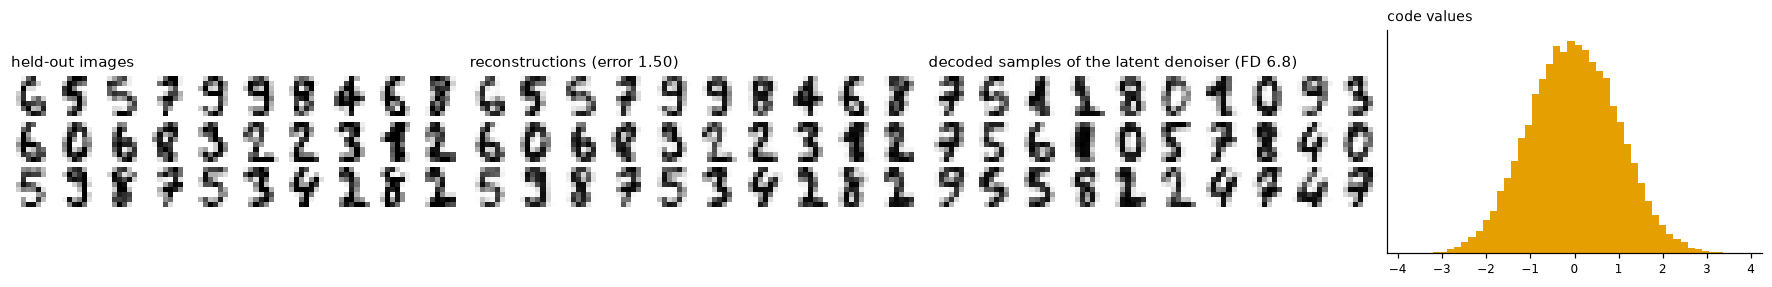

In [12]:
def regulariser_explorer(autoencoder="KL weight 0.01"):
    a = aes[autoencoder]
    fig, axes = plt.subplots(1, 4, figsize=(16, 2.5), gridspec_kw=dict(width_ratios=[1.2, 1.2, 1.2, 1]))
    images.show_grid(Xte[:30], nrow=10, ax=axes[0], title="held-out images")
    images.show_grid(a["rec"][:30], nrow=10, ax=axes[1], title=f"reconstructions (error {a['row']['reconstruction error']:.2f})")
    images.show_grid(a["samples"][:30], nrow=10, ax=axes[2], title=f"decoded samples of the latent denoiser (FD {a['row']['samples: fd']:.1f})")
    axes[3].hist(a["lat"].z.flatten().numpy(), bins=50, range=(-4, 4), density=True, color=viz.ORANGE); axes[3].set_yticks([]); axes[3].set_title("code values", fontsize=9)
    plt.show()
viz.explore(regulariser_explorer, autoencoder=["KL weight 0.01"] + [n for n in AES if n != "KL weight 0.01"])

## 8. Assembling the parts: text-conditioned latent diffusion

Now the three parts meet. The autoencoder is retrained on the images in both styles. The denoiser works on its
codes. Its condition is no longer a class label but the **embedding of a caption**, a vector of 32 numbers, with the
all-zero vector as "no caption" for classifier-free guidance.

Which text encoder should produce that vector? This was a real design decision. Stable Diffusion uses the text
encoder of CLIP ([Rombach et al., 2021](https://arxiv.org/abs/2112.10752)). DALL·E 2 conditions on CLIP embeddings as well ([Ramesh et al., 2022](https://arxiv.org/abs/2204.06125)). Imagen uses a
language model trained on text alone and reports that a larger text encoder matters more than a larger denoiser
([Saharia et al., 2022](https://arxiv.org/abs/2205.11487)). All three freeze it, where earlier systems trained a text encoder together with the generator. Why?

The experiment below gives one reason. The denoiser is trained on a **narrow** set of captions: the digit always
spelled as a word, and the style always called "thin" or "bold". We compare three text encoders:

* the **frozen text encoder of our CLIP model**, which saw all the wordings during its own pretraining;
* a text encoder **trained from scratch together with the denoiser**, which sees only the narrow captions;
* a **frozen text encoder with random weights**, as a control.

Each model is then prompted with wordings that the *denoiser* never saw during its training: the synonyms "thick"
and "heavy", and numerals.

In [13]:
set_seed(0); ae2 = L.Autoencoder(16, "kl"); L.train_autoencoder(ae2, Xc, weight=0.01)             # the autoencoder, now for both styles
lat2 = L.Latents(ae2, Xc); text_diff = D.Diffusion(**FINAL)
narrow = L.caption_table(numerals=False, synonyms=(0,))                                             # captions for training the denoiser: words only, "thin" / "bold" only
ink = Xct.mean(1); INK = float((ink[sct == 0].mean() + ink[sct == 1].mean()) / 2)                    # a bold image has more ink than this, a thin one less
print(f"{narrow.shape[2]} training captions per (digit, style) out of {L.caption_table().shape[2]} possible; e.g.", [" ".join(V.VOCAB[i] for i in row if i) for row in narrow[3, 1, :3]])
print(f"the ink threshold separates the two styles of real held-out images with accuracy {float(((ink > INK).long() == sct).float().mean()):.3f}")

def prompt_batch(style_word=0, numerals=False, n_each=18):
    ds = torch.arange(10).repeat_interleave(n_each).repeat(2); ss = torch.arange(2).repeat_interleave(10 * n_each)
    toks = torch.stack([V.encode_caption(f"a {V.STYLE_WORDS[int(s)][style_word]} {int(d) if numerals else V.DIGIT_WORDS[int(d)]}") for d, s in zip(ds, ss)])
    return toks, ds, ss

def generate(run, tokens, w=1.0, seed=0, **kw):
    with torch.no_grad():
        c = run["embed"](tokens)
    return lat2.decode(text_diff.sample(run["model"], c, steps=50, w=w, seed=seed, clip=False, **kw))

def follow(run, w=1.0, **prompt):
    toks, ds, ss = prompt_batch(**prompt); x = generate(run, toks, w)
    with torch.no_grad():
        return f"{float((judge(x).argmax(1) == ds).float().mean()):.2f} / {float(((x.mean(1) > INK).long() == ss).float().mean()):.2f}"

text_runs = {}
for name in ("frozen CLIP text encoder", "text encoder trained with the denoiser", "frozen random text encoder"):
    set_seed(0); model = D.Denoiser(128, 3, d_in=16, cond_dim=32); trainable = None
    if name == "frozen CLIP text encoder":
        embed = clip.embed_text
    else:
        set_seed(1); enc = V.TextEncoder().eval(); embed = lambda t, enc=enc: F.normalize(enc(t), dim=-1)
        trainable = enc if name == "text encoder trained with the denoiser" else None
    out = L.train_text_diffusion(model, text_diff, lat2.z, dc, sc, embed, text_encoder=trainable, table=narrow)
    if trainable is not None:
        trainable.eval()
    text_runs[name] = dict(model=out["model"], embed=embed, seconds=out["seconds"])
tests = {'wording seen by the denoiser: "a bold three"': {}, 'new style word: "a thick three"': dict(style_word=1), 'new style word: "a heavy three"': dict(style_word=2),
         'numeral: "a bold 3"': dict(numerals=True), 'both new: "a thick 3"': dict(style_word=1, numerals=True)}
followed = pd.DataFrame({name: {t: follow(run, **kw) for t, kw in tests.items()} for name, run in text_runs.items()})
print("share of 360 samples with the requested digit / the requested style (guidance scale 1; chance is 0.10 / 0.50)")
display(followed)
print({n: f"{r['seconds']:.0f} s" for n, r in text_runs.items()})

7 training captions per (digit, style) out of 34 possible; e.g. ['a bold three', 'a picture of a bold three', 'a three']
the ink threshold separates the two styles of real held-out images with accuracy 0.981
share of 360 samples with the requested digit / the requested style (guidance scale 1; chance is 0.10 / 0.50)


,frozen CLIP text encoder,text encoder trained with the denoiser,frozen random text encoder
"wording seen by the denoiser: ""a bold three""",0.99 / 0.99,0.99 / 0.99,0.99 / 0.99
"new style word: ""a thick three""",0.99 / 0.99,0.98 / 0.55,0.84 / 0.46
"new style word: ""a heavy three""",0.99 / 0.99,0.99 / 0.54,0.88 / 0.51
"numeral: ""a bold 3""",0.99 / 0.99,0.10 / 1.00,0.15 / 0.97
"both new: ""a thick 3""",0.99 / 0.99,0.08 / 0.61,0.17 / 0.47


{'frozen CLIP text encoder': '14 s', 'text encoder trained with the denoiser': '24 s', 'frozen random text encoder': '14 s'}


**What happened.** Each cell gives the share of samples with the requested digit and with the requested style.

* **On the wording used in training, all three text encoders work**: 0.99 and 0.99, including the encoder with
  random weights. For captions that the denoiser has seen, any fixed function that tells the captions apart is
  enough.
* **On new wordings, only the pretrained encoder works.** With the frozen CLIP encoder, "a thick three",
  "a heavy three", "a bold 3" and "a thick 3" are followed as well as the training wording (0.99 and 0.99). The
  denoiser never saw these words. The text encoder had seen them in its own pretraining, and it maps them to
  nearly the same vector as the wording the denoiser knows (section 5: similarities of 0.98 and 0.99).
* **The encoder trained with the denoiser fails exactly where its data stop.** For "a thick three" the digit is
  right (0.98) and the style is at chance (0.55). For "a bold 3" the style is right (1.00) and the digit is at
  chance (0.10). It learned the words it was shown and nothing about the others. The random encoder fails in the
  same places.
* Training the text encoder with the denoiser was also slower (24 s against 14 s).

This is one reason for the division of labour. Images with captions are scarce, and their captions are narrow.
Text alone, or text with images at the scale of CLIP, covers far more ways of saying a thing. A frozen pretrained
text encoder brings that coverage to the denoiser without any more paired data.

The grids below show the same result as images. In the rows whose prompts use a numeral (3, 5, 6 and 8), the model
on the right mostly draws other digits.

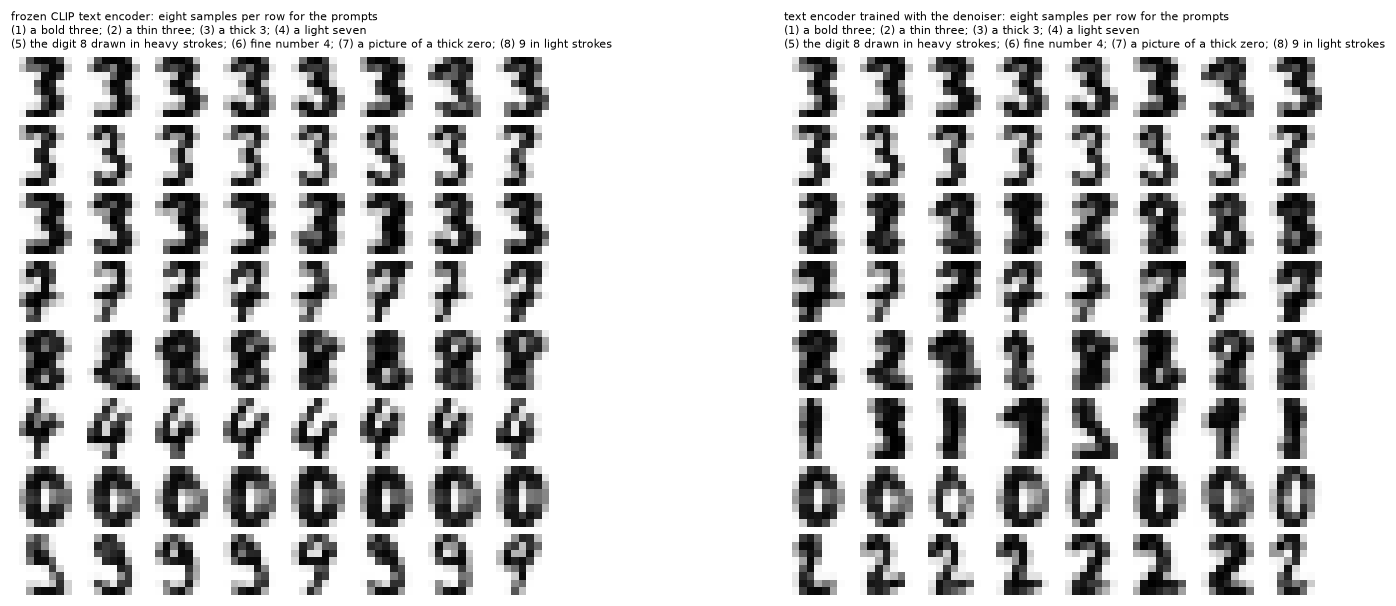

saved figures/nb08_latent_sampling.gif  (30 frames, 474 kB)


'figures/nb08_latent_sampling.gif'

In [14]:
PROMPTS = ["a bold three", "a thin three", "a thick 3", "a light seven", "the digit 8 drawn in heavy strokes", "fine number 4", "a picture of a thick zero", "9 in light strokes"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
for ax, name in zip(axes, ("frozen CLIP text encoder", "text encoder trained with the denoiser")):
    toks = torch.stack([V.encode_caption(p) for p in PROMPTS]).repeat_interleave(8, 0)
    images.show_grid(generate(text_runs[name], toks, w=1.0), nrow=8, ax=ax)
    ax.set_title(f"{name}: eight samples per row for the prompts\n" + "; ".join(f"({i + 1}) {p}" for i, p in enumerate(PROMPTS[:4])) + "\n" + "; ".join(f"({i + 5}) {p}" for i, p in enumerate(PROMPTS[4:])), fontsize=7)
plt.show()

run = text_runs["frozen CLIP text encoder"]
toks16 = torch.stack([V.encode_caption(p) for p in PROMPTS]).repeat_interleave(2, 0)
with torch.no_grad():
    _, frames = text_diff.sample(run["model"], run["embed"](toks16), steps=50, w=1.0, clip=False, record=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 2.1))
def frame(k):
    t, zt, z0 = frames[k]
    for ax in axes:
        ax.clear()
    images.show_grid(lat2.decode(zt), nrow=8, ax=axes[0]); axes[0].set_title(f"the noisy code at t = {t}, decoded", fontsize=10)
    images.show_grid(lat2.decode(z0), nrow=8, ax=axes[1]); axes[1].set_title("the denoiser's estimate of the clean code, decoded", fontsize=10)
viz.save_gif(fig, frame, list(range(0, 50, 2)) + [49] * 5, "nb08_latent_sampling.gif", fps=5)

![Sampling in the latent space, shown through the decoder: two samples for each of eight prompts](figures/nb08_latent_sampling.gif)

### Try it: write a prompt

Static preview at the default settings {'style': 'bold', 'digit': 'three', 'wording': 'a {style} {digit}', 'guidance': 1.0, 'text_encoder': 'frozen CLIP text encoder'}. Run the notebook to get the controls.


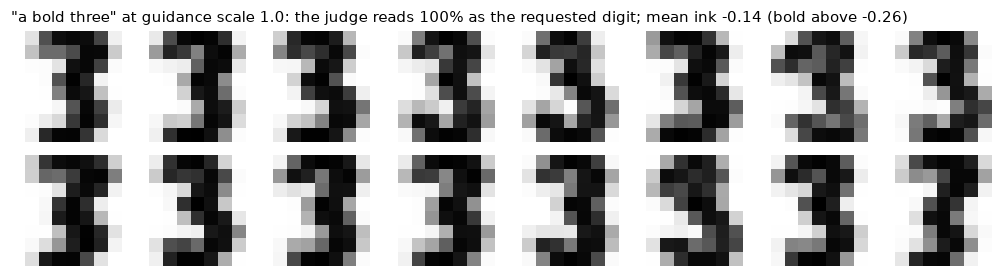

In [15]:
def prompt_explorer(style="bold", digit="three", wording="a {style} {digit}", guidance=1.0, text_encoder="frozen CLIP text encoder"):
    text = wording.format(style=style, digit=digit)
    want = V.DIGIT_WORDS.index(digit) if digit in V.DIGIT_WORDS else int(digit)
    x = generate(text_runs[text_encoder], V.encode_caption(text)[None].repeat(16, 1), w=guidance)
    with torch.no_grad():
        right = float((judge(x).argmax(1) == want).float().mean())
    fig, ax = plt.subplots(figsize=(9, 2.6))
    images.show_grid(x, nrow=8, ax=ax, title=f'"{text}" at guidance scale {guidance:.1f}: the judge reads {right:.0%} as the requested digit; mean ink {float(x.mean()):+.2f} (bold above {INK:+.2f})')
    plt.show()
viz.explore(prompt_explorer, style=["bold", "thin", "thick", "fine", "heavy", "light"], digit=["three"] + [w for w in V.DIGIT_WORDS if w != "three"] + [str(i) for i in range(10)],
            wording=["a {style} {digit}", "the digit {digit} drawn in {style} strokes", "{digit} in {style} strokes"], guidance=(0.0, 6.0, 0.5, 1.0),
            text_encoder=["frozen CLIP text encoder", "text encoder trained with the denoiser", "frozen random text encoder"])

## 9. Scorecard

In [16]:
keep = ["diffusion on pixels (notebook 07 recipe)", "latent diffusion, no regulariser", "latent diffusion, KL weight 0.01", "latent diffusion, KL weight 1",
        "latent diffusion, VQ: 4 tokens from 64 codes (24 bits)", "latent diffusion, VQ: 8 tokens from 64 codes (48 bits)"]
display(pd.DataFrame([ROWS[n] for n in keep]).set_index("model")[["fd", "precision", "coverage", "nn_ratio", "judge_acc", "nfe"]].round(2))
print("linear probes (held-out accuracy):")
display(pd.DataFrame(PROBES).T.round(3))
rows = [dict(model=n, family="image", **{k: ROWS[n].get(k) for k in ("fd", "precision", "coverage", "nn_ratio", "judge_acc", "nfe")}) for n in keep]
metrics.append_rows(rows, "08_parts");

,fd,precision,coverage,nn_ratio,judge_acc,nfe
model,,,,,,
diffusion on pixels (notebook 07 recipe),7.82,0.96,0.94,0.92,0.96,50
"latent diffusion, no regulariser",6.50,0.96,0.98,0.93,0.92,50
"latent diffusion, KL weight 0.01",6.78,0.97,0.94,0.96,0.95,50
"latent diffusion, KL weight 1",40.12,0.90,0.72,0.96,0.93,50
"latent diffusion, VQ: 4 tokens from 64 codes (24 bits)",12.15,0.96,0.90,0.93,0.94,50
"latent diffusion, VQ: 8 tokens from 64 codes (48 bits)",8.69,0.94,0.93,0.93,0.96,50


linear probes (held-out accuracy):


,1 label per digit,5 labels per digit,20 labels per digit,"all 1,438 labels"
raw pixels,0.622,0.846,0.920,0.972
encoder with random weights,0.201,0.382,0.575,0.747
"MAE, 50% hidden",0.722,0.863,0.920,0.944
contrastive,0.733,0.876,0.927,0.967
CLIP image encoder,0.943,0.962,0.968,0.978


**Reading the scorecard.** Latent diffusion on a lightly regularised code of 16 numbers matches diffusion on 64
pixels (FD 6.5 and 6.8 against 7.8), and the quality of the autoencoder decides how good it can get. The probe
table adds the image encoder of the text-image model, which Challenge 1 discusses.

All the parts of a text-to-image system now exist at toy scale: an autoencoder, a text encoder, and a denoiser that
works on codes and is conditioned on text. One part is still from another era. The denoiser is an MLP that treats
its input as an unordered list of numbers. Notebook 09 replaces it with a transformer.

## 10. Design choices: what changed, and the parts of well-known systems

| Choice | Earlier | Moved to | Why | Measured here |
|---|---|---|---|---|
| Vision backbone | Convolutional networks | Transformer on patches ([Dosovitskiy et al., 2020](https://arxiv.org/abs/2010.11929)) | One architecture for text and images; scales with data | Used throughout; not compared with a convolutional network |
| Pretraining a vision encoder | Supervised, on labels | Contrastive ([Chen et al., 2020](https://arxiv.org/abs/2002.05709)); masked autoencoding ([He et al., 2021](https://arxiv.org/abs/2111.06377)) | Labels are scarce and images are not | Probe with 1 label per digit: contrastive 0.73, MAE 0.72, raw pixels 0.62, same encoder from scratch 0.19. Level with raw pixels from 20 labels on |
| MAE mask ratio | 15% (the habit from BERT) | 75% ([He et al., 2021](https://arxiv.org/abs/2111.06377)) | Neighbouring patches make a small mask too easy | 50% and 75% hidden were best (0.72 and 0.70 with 1 label); 25% and 90% were worse than raw pixels |
| Contrastive views | None | Strong augmentation; large batch; low temperature ([Chen et al., 2020](https://arxiv.org/abs/2002.05709)) | The views decide what the features ignore | 1 label per digit: 0.73; without the shift 0.56; temperature 1.0: 0.64; batch 32: 0.51 (which also means less data) |
| Supervision for images | Class labels | Captions ([Radford et al., 2021](https://arxiv.org/abs/2103.00020)) | Captions are free and open-vocabulary | Zero-shot digit accuracy 0.97 with no class labels; 0.45 for digit and style on combinations never seen |
| Text-image loss | Softmax over the batch | Sigmoid per pair ([Zhai et al., 2023](https://arxiv.org/abs/2303.15343)) | No normalisation over the batch | Softmax ahead in single runs (0.92 against 0.88 at batch 64); the advantage of large batches was the data |
| Where diffusion runs | Pixels | Codes of an autoencoder ([Rombach et al., 2021](https://arxiv.org/abs/2112.10752)) | Compute, at high resolution | FD 6.5 to 6.8 on 16 numbers against 7.8 on 64 pixels; no time saved at this size |
| Regulariser of the codes | Strong KL (the VAE) | KL with a tiny weight, or quantisation ([Oord et al., 2017](https://arxiv.org/abs/1711.00937), [Esser et al., 2020](https://arxiv.org/abs/2012.09841)) | A second model learns the codes, so the prior need not | FD 6.5 with no regulariser, 6.8 at KL weight 0.01, 40.1 at weight 1; quantised codes 8.7 to 12.2 |
| Text encoder of the denoiser | Trained with the generator | Pretrained and frozen ([Rombach et al., 2021](https://arxiv.org/abs/2112.10752), [Saharia et al., 2022](https://arxiv.org/abs/2205.11487)) | It knows wordings that the paired data lack | New wordings: digit and style right for 0.99 with frozen CLIP; one of the two at chance with a text encoder trained with the denoiser |

**The pretrained parts of some well-known systems**, as published.

| System | Text encoder | Where the denoiser works | Notes |
|---|---|---|---|
| DALL·E 2 ([Ramesh et al., 2022](https://arxiv.org/abs/2204.06125)) | CLIP | Pixels, with upsamplers | A separate "prior" model maps the text embedding to a CLIP image embedding |
| Imagen ([Saharia et al., 2022](https://arxiv.org/abs/2205.11487)) | T5, a language model trained on text only | Pixels, with upsamplers | Reports that scaling the text encoder helps more than scaling the denoiser |
| Stable Diffusion 1 ([Rombach et al., 2021](https://arxiv.org/abs/2112.10752)) | CLIP | Codes of a KL autoencoder, 8 times smaller per side, 4 channels | The design this notebook follows |
| Stable Diffusion 3 ([Esser et al., 2024](https://arxiv.org/abs/2403.03206)) | Two CLIP models and T5 | Codes with 16 channels | The denoiser is a transformer (notebook 09) |

## Challenge Problem 1: Which pretraining gives the best features?

Part B trained an image encoder as one half of the CLIP model, and section 5 probed it (`PROBES["CLIP image encoder"]`). Put its linear-probe
accuracies next to those of the MAE and contrastive encoders of part A and of raw pixels, for 1, 5 and 20 labels per digit, and plot them. The three
encoders have the same architecture. Why is one of them so far ahead with a single label per digit, and is the comparison fair?

In [17]:
# Start your code here

### Challenge Problem 1 Solution

,1 label per digit,5 labels per digit,20 labels per digit,"all 1,438 labels"
raw pixels,0.622,0.846,0.920,0.972
"MAE, 50% hidden",0.722,0.863,0.920,0.944
contrastive,0.733,0.876,0.927,0.967
CLIP image encoder,0.943,0.962,0.968,0.978


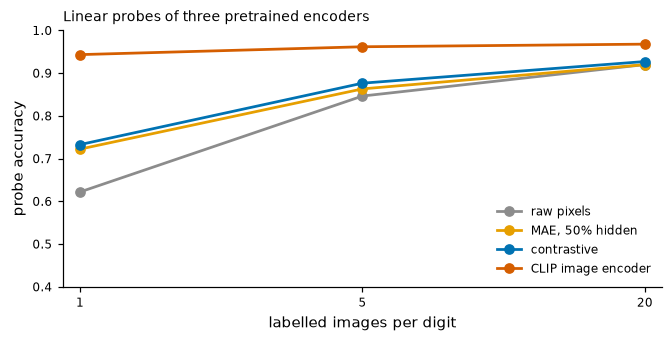

In [18]:
names = ["raw pixels", [n for n in PROBES if n.startswith("MAE")][0], "contrastive", "CLIP image encoder"]
t = pd.DataFrame(PROBES).T.loc[names]
display(t.round(3))
fig, ax = plt.subplots(figsize=(6, 3))
for n, col in zip(names, (viz.GREY, viz.ORANGE, viz.BLUE, viz.VERMILION)):
    ax.plot(range(3), t.loc[n].iloc[:3], "o-", color=col, label=n)
ax.set_xticks(range(3)); ax.set_xticklabels(["1", "5", "20"]); ax.set_xlabel("labelled images per digit"); ax.set_ylabel("probe accuracy"); ax.set_ylim(0.4, 1); ax.legend(fontsize=8, loc="lower right")
ax.set_title("Linear probes of three pretrained encoders", fontsize=9); plt.show()
# Read the table. The image encoder of the text-image model is far ahead with few labels: 0.94 with one label per
# digit, against 0.73 (contrastive), 0.72 (MAE) and 0.62 (raw pixels). With all labels the four are close (0.94 to 0.98).
# The comparison is not fair, and seeing why is the point of the exercise. MAE and contrastive pretraining used images
# only. The text-image model was trained on captions, and every caption names the digit. Matching an image to a caption
# that says "three" is classification with the label written out in words. Its encoder has in effect seen a label for
# every training image. What it learned without being asked is the rest: wordings, synonyms and the style.
# The same holds for the real CLIP. Its supervision is noisier than class labels and vastly more plentiful, and it is
# not "label-free" in the sense in which MAE is.

## Challenge Problem 2: The guidance scale of the text-conditioned model

Section 8 sampled at a guidance scale of 1. Using `prompt_batch()` and `generate(run, tokens, w)` with the frozen CLIP text encoder, measure the share
of samples with the requested digit and the requested style at guidance scales 0, 0.5, 1, 2, 4 and 8, together with the mean distance between two samples
of the same prompt (a measure of variety). Show eight samples of "a thin seven" at each scale. Does guidance help, and what does it cost?

In [19]:
# Start your code here

### Challenge Problem 2 Solution

,requested digit,requested style,contrast,distance between two samples of one prompt
guidance scale,,,,
0.0,0.894,0.914,0.436,4.326
0.5,0.981,0.975,0.442,3.828
1.0,0.986,0.989,0.445,3.549
2.0,0.997,1.000,0.449,3.221
4.0,1.000,0.997,0.452,2.859
8.0,1.000,0.997,0.454,2.503


real held-out images: mean distance between two images of the same digit and style 4.49


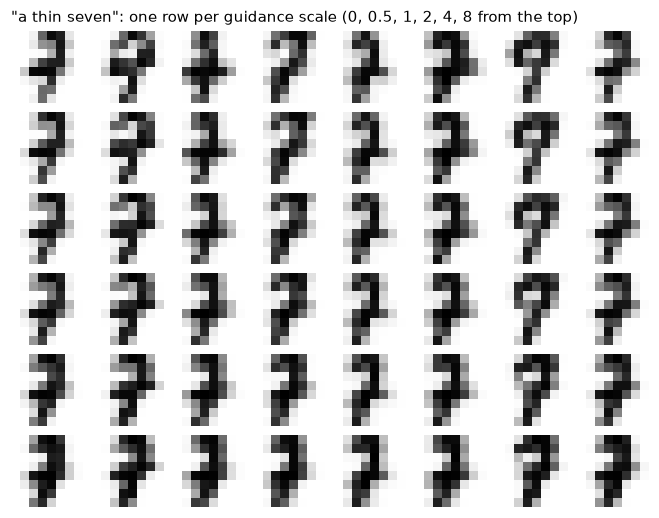

In [20]:
run = text_runs["frozen CLIP text encoder"]; toks, ds, ss = prompt_batch()
scales, out, shown = [0.0, 0.5, 1.0, 2.0, 4.0, 8.0], {}, []
for w in scales:
    x = generate(run, toks, w)
    with torch.no_grad():
        out[w] = {"requested digit": float((judge(x).argmax(1) == ds).float().mean()), "requested style": float(((x.mean(1) > INK).long() == ss).float().mean()),
                  "contrast": G.contrast(x), "distance between two samples of one prompt": float(torch.stack([torch.pdist(g).mean() for g in x.view(20, 18, 64)]).mean())}
    shown.append(generate(run, V.encode_caption("a thin seven")[None].repeat(8, 1), w))
t = pd.DataFrame(out).T; t.index.name = "guidance scale"
display(t.round(3))
real_d = float(torch.stack([torch.pdist(Xct[(dct == d) & (sct == s)][:18]).mean() for s in (0, 1) for d in range(10)]).mean())
print(f"real held-out images: mean distance between two images of the same digit and style {real_d:.2f}")
fig, ax = plt.subplots(figsize=(7, 4.6))
images.show_grid(torch.cat(shown), nrow=8, ax=ax, title='"a thin seven": one row per guidance scale (0, 0.5, 1, 2, 4, 8 from the top)')
plt.show()
# Read the table. Guidance helps both properties, and most of the gain comes early: from scale 0 to 0.5 the share
# with the requested digit rises from 0.89 to 0.98 and with the requested style from 0.91 to 0.98. From scale 2 on
# both are at 1.00.
# The cost is variety. Two samples of one prompt are 4.33 apart without guidance, close to two real images of the
# same digit and style (4.49). The distance falls steadily with the scale: 3.55 at scale 1, 2.86 at 4 and 2.50 at 8.
# The images do not break at the highest scale; the contrast barely moves (0.44 to 0.45). In the rows of sevens the
# samples simply become more alike. Guidance buys fidelity to the prompt with diversity, as in notebook 07, and
# beyond a scale of about 1 to 2 there is nothing left to buy here.

## Final summary

* **Vision transformer.** An image becomes a sequence of patch tokens, and the transformer of notebook 03 is applied
  unchanged.
* **Masked autoencoding.** Hiding 50 to 75% of the patches gave the best features. Hiding 25% or 90% gave features
  worse than raw pixels.
* **Contrastive learning.** Features come from agreeing on two views of an image. The choice of views mattered
  most: without the shift, the features were worse than raw pixels.
* **What pretraining bought.** A great deal against the same encoder trained from scratch on few labels (0.73
  against 0.19 with one label per digit). About ten points against a linear classifier on raw pixels, and nothing
  from twenty labels on. Digits of 8×8 pixels leave an encoder little to add.
* **Text-image model.** Trained only on images with captions, it classified held-out digits at 0.97 from prompts
  and learned that "thick" and "bold" mean the same. On combinations of digit and style it had not seen, it was
  right for 0.45. Its apparent need for large batches was a need for data.
* **Autoencoder.** The decoder sets the ceiling for latent diffusion, so the codes should be regularised as little
  as the denoiser tolerates: FD 6.5 with no regulariser, 40.1 with the KL weight of a VAE.
* **Latent diffusion.** On 16 numbers per image it matched diffusion on 64 pixels. It saved no time at this size.
* **Text encoder.** With a frozen, pretrained text encoder the denoiser followed wordings it was never trained on
  (0.99). With a text encoder trained alongside it, it was at chance on them.
* **Next.** Notebook 09 replaces the MLP denoiser with a transformer over patches, and the curved path between
  noise and data with a straight one.

## References

* Alexey Dosovitskiy, Lucas Beyer, Alexander Kolesnikov et al. (2020). **An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale**. arXiv:2010.11929. [arxiv.org/abs/2010.11929](https://arxiv.org/abs/2010.11929)
* Kaiming He, Xinlei Chen, Saining Xie et al. (2021). **Masked Autoencoders Are Scalable Vision Learners**. arXiv:2111.06377. [arxiv.org/abs/2111.06377](https://arxiv.org/abs/2111.06377)
* Ting Chen, Simon Kornblith, Mohammad Norouzi et al. (2020). **A Simple Framework for Contrastive Learning of Visual Representations**. arXiv:2002.05709. [arxiv.org/abs/2002.05709](https://arxiv.org/abs/2002.05709)
* Alec Radford, Jong Wook Kim, Chris Hallacy et al. (2021). **Learning Transferable Visual Models From Natural Language Supervision**. arXiv:2103.00020. [arxiv.org/abs/2103.00020](https://arxiv.org/abs/2103.00020)
* Xiaohua Zhai, Basil Mustafa, Alexander Kolesnikov et al. (2023). **Sigmoid Loss for Language Image Pre-Training**. arXiv:2303.15343. [arxiv.org/abs/2303.15343](https://arxiv.org/abs/2303.15343)
* Aaron van den Oord, Oriol Vinyals, Koray Kavukcuoglu (2017). **Neural Discrete Representation Learning**. arXiv:1711.00937. [arxiv.org/abs/1711.00937](https://arxiv.org/abs/1711.00937)
* Patrick Esser, Robin Rombach, Björn Ommer (2020). **Taming Transformers for High-Resolution Image Synthesis**. arXiv:2012.09841. [arxiv.org/abs/2012.09841](https://arxiv.org/abs/2012.09841)
* Robin Rombach, Andreas Blattmann, Dominik Lorenz et al. (2021). **High-Resolution Image Synthesis with Latent Diffusion Models**. arXiv:2112.10752. [arxiv.org/abs/2112.10752](https://arxiv.org/abs/2112.10752)
* Chitwan Saharia, William Chan, Saurabh Saxena et al. (2022). **Photorealistic Text-to-Image Diffusion Models with Deep Language Understanding**. arXiv:2205.11487. [arxiv.org/abs/2205.11487](https://arxiv.org/abs/2205.11487)
* Aditya Ramesh, Prafulla Dhariwal, Alex Nichol et al. (2022). **Hierarchical Text-Conditional Image Generation with CLIP Latents**. arXiv:2204.06125. [arxiv.org/abs/2204.06125](https://arxiv.org/abs/2204.06125)
* Patrick Esser, Sumith Kulal, Andreas Blattmann et al. (2024). **Scaling Rectified Flow Transformers for High-Resolution Image Synthesis**. arXiv:2403.03206. [arxiv.org/abs/2403.03206](https://arxiv.org/abs/2403.03206)

The full, verified list for the series is in [`research_papers/README.md`](research_papers/README.md).